# GPS Anomaly Detection — Unsupervised Machine Learning

**Project:** GPS Digital Twin with LLM Agent — PFA iDIRTECH
**Dataset:** Porto Taxi Trajectory (ECML/PKDD 2015) — 444 taxis, 1.7M trips
**Goal:** Compare a rule-based anomaly detector against unsupervised ML models (Isolation Forest)

---

## Pipeline

```
Raw GPS pings (lat, lon)
        v
UTM projection (zone 29N) -> meters
        v
Kalman filter per taxi -> [x, y, vx, vy]
        v
Feature extraction (6 features per ping)
        v
Isolation Forest (unsupervised)
        v
Comparison vs rule-based detector
```

## 1. Setup

In [2]:
!pip install filterpy pyproj -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 8.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pyproj import Proj
from ast import literal_eval
from tqdm import tqdm
from filterpy.kalman import KalmanFilter

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Libraries loaded")

Libraries loaded


## 2. Kalman Filter

Same implementation as the production pipeline (`twin/kalman_filter.py`).

- State vector: `[x, y, vx, vy]` — position and velocity in UTM meters
- Constant-velocity motion model, `dt = 15s` (Porto ping interval)
- `R = 9.0` — GPS measurement noise (~3m std dev)
- `Q = 0.01` — process noise, tuned for smooth velocity estimates
- `P = 500` — initial uncertainty

In [4]:
def create_vehicle_filter(dt: float = 15.0) -> KalmanFilter:
    """
    Create a Kalman filter for vehicle tracking.

    Parameters:
        dt (float): Time step in seconds. Default 15.0 (Porto ping interval).

    Returns:
        KalmanFilter: Configured Kalman filter instance.
    """
    kf = KalmanFilter(dim_x=4, dim_z=2)

    # State transition — constant velocity model
    kf.F = np.array([[1, 0, dt, 0],
                     [0, 1, 0, dt],
                     [0, 0, 1,  0],
                     [0, 0, 0,  1]])

    # Measurement matrix — GPS observes position only
    kf.H = np.array([[1, 0, 0, 0],
                     [0, 1, 0, 0]])

    kf.R = np.eye(2) * 9.0      # GPS noise ~3m std dev -> variance 9
    kf.P = np.eye(4) * 500.0    # initial uncertainty
    kf.Q = np.eye(4) * 0.01     # process noise
    kf.x = np.zeros((4, 1))     # initial state
    return kf


class VehicleTwin:
    """Digital twin for one vehicle — wraps a Kalman filter."""

    def __init__(self, taxi_id: str):
        self.taxi_id = taxi_id
        self.kf = create_vehicle_filter()
        self.initialized = False
        self.last_x = None
        self.last_y = None

    def update(self, x: float, y: float) -> dict:
        """
        Run one predict-update cycle with a new GPS measurement.

        Parameters:
            x (float): Easting in UTM meters.
            y (float): Northing in UTM meters.

        Returns:
            dict: Filtered state estimate.
        """
        if not self.initialized:
            self.kf.x = np.array([[x], [y], [0], [0]])
            self.initialized = True
        else:
            self.kf.predict()
            self.kf.update(np.array([[x], [y]]))

        prev_x, prev_y = self.last_x, self.last_y
        self.last_x = float(self.kf.x[0])
        self.last_y = float(self.kf.x[1])

        return {
            "taxi_id": self.taxi_id,
            "x": float(self.kf.x[0]),
            "y": float(self.kf.x[1]),
            "vx": float(self.kf.x[2]),
            "vy": float(self.kf.x[3]),
            "speed": float(np.sqrt(self.kf.x[2]**2 + self.kf.x[3]**2)),
            "uncertainty": float(np.trace(self.kf.P)),
            "prev_x": prev_x,
            "prev_y": prev_y
        }

print("Kalman filter defined")

Kalman filter defined


## 3. UTM Projection

The Kalman filter operates in Euclidean space. GPS coordinates in degrees are not metric — 1 degree of longitude is ~84km at Porto's latitude but ~111km at the equator. UTM zone 29N converts lat/lon to meters so distances and velocities are physically meaningful.

In [5]:
UTM_ZONE = Proj(proj="utm", zone=29, ellps="WGS84")

def latlon_to_meters(lat: float, lon: float) -> tuple:
    """
    Convert WGS84 lat/lon to UTM zone 29N coordinates in meters.

    Parameters:
        lat (float): Latitude in decimal degrees.
        lon (float): Longitude in decimal degrees.

    Returns:
        tuple: (x, y) in meters.
    """
    x, y = UTM_ZONE(lon, lat)   # pyproj expects (lon, lat)
    return x, y

# sanity check
print(latlon_to_meters(41.148, -8.610))

(532726.1536538537, 4555259.966858393)


## 4. Load & Clean Dataset

Filters applied:
- Remove trips flagged `MISSING_DATA = True`
- Remove trips with empty POLYLINE
- Parse POLYLINE string into a Python list of `[lon, lat]` pairs

In [6]:
DATA_PATH = "/kaggle/input/datasets/abdeljalilnahimy/taxi-trajectory/train.csv"

df = pd.read_csv(DATA_PATH, usecols=["TAXI_ID", "MISSING_DATA", "POLYLINE"])

df = df[df["MISSING_DATA"] == False]
df = df[df["POLYLINE"] != "[]"]
df = df.drop(columns=["MISSING_DATA"])
df["POLYLINE"] = df["POLYLINE"].apply(literal_eval)

print(f"Total trips: {len(df):,}")
print(f"Total taxis: {df['TAXI_ID'].nunique()}")
print(f"Sample POLYLINE: {df['POLYLINE'].iloc[0][:3]}")

Total trips: 1,704,759
Total taxis: 444
Sample POLYLINE: [[-8.618643, 41.141412], [-8.618499, 41.141376], [-8.620326, 41.14251]]


## 5. Feature Extraction

For each taxi, a fresh Kalman filter processes every ping of every trip sequentially.
`prev_x` / `prev_y` reset at the start of each trip — the gap between the last ping of one
trip and the first ping of the next is not a real position jump.

The first ping per taxi is skipped: at that point the filter is still initialising
(`uncertainty = 2000`, `speed = 0`) and those values are artefacts, not measurements.

**Scope:** 200 trips per taxi. All 444 taxis are represented while keeping runtime
tractable (~6 min vs ~2h for the full 83M-ping dataset). For an unsupervised model,
4.3M samples is well past the point where additional data shifts the decision boundary.

In [7]:
TRIPS_PER_TAXI = 200

df_sample = df.groupby("TAXI_ID").head(TRIPS_PER_TAXI).reset_index(drop=True)
print(f"Trips selected: {len(df_sample):,}")

all_features = []

for taxi_id, taxi_trips in tqdm(df_sample.groupby("TAXI_ID"), desc="Processing taxis"):
    twin = VehicleTwin(str(int(taxi_id)))

    for _, trip in taxi_trips.iterrows():
        prev_x, prev_y = None, None   # reset per trip

        for lon, lat in trip["POLYLINE"]:
            x, y = latlon_to_meters(lat, lon)
            state = twin.update(x, y)

            jump = 0.0
            if prev_x is not None:
                jump = np.sqrt((state["x"] - prev_x)**2 + (state["y"] - prev_y)**2)

            # skip first ping per taxi — filter not initialised
            if state["prev_x"] is not None:
                all_features.append({
                    "taxi_id": taxi_id,
                    "speed": state["speed"],
                    "vx": state["vx"],
                    "vy": state["vy"],
                    "uncertainty": state["uncertainty"],
                    "jump_distance": jump
                })

            prev_x, prev_y = state["x"], state["y"]

feat_df = pd.DataFrame(all_features)

# temporal context features
feat_df["rolling_mean_speed"] = feat_df.groupby("taxi_id")["speed"].transform(
    lambda s: s.rolling(5, min_periods=1).mean()
)
feat_df["rolling_std_speed"] = feat_df.groupby("taxi_id")["speed"].transform(
    lambda s: s.rolling(5, min_periods=1).std().fillna(0)
)

feat_df.to_csv("/kaggle/working/porto_features.csv", index=False)

print(f"\nTotal pings: {len(feat_df):,}")
print(f"Columns: {feat_df.columns.tolist()}")
feat_df.head()

Trips selected: 87,573


Processing taxis: 100%|██████████| 444/444 [05:38<00:00,  1.31it/s]



Total pings: 4,311,098
Columns: ['taxi_id', 'speed', 'vx', 'vy', 'uncertainty', 'jump_distance', 'rolling_mean_speed', 'rolling_std_speed']


,taxi_id,speed,vx,vy,uncertainty,jump_distance,rolling_mean_speed,rolling_std_speed
0,20000001,5.377567,-5.205093,-1.351013,22.522721,81.022019,5.377567,0.000000
1,20000001,12.975293,-12.098592,4.688529,17.870913,199.116819,9.176430,5.372403
2,20000001,11.181125,-10.362825,4.198742,15.057833,150.686135,9.844662,3.971267
3,20000001,6.919200,-6.415520,2.591609,13.114579,37.993158,9.113296,3.557184
4,20000001,3.755060,-3.489847,1.386163,12.085720,1.519105,8.041649,3.902859


### Feature reference

| Feature | Source | Signal captured |
|---|---|---|
| `speed` | `sqrt(vx^2 + vy^2)` from Kalman | velocity magnitude |
| `vx` | Kalman state `x[2]` | East-West velocity |
| `vy` | Kalman state `x[3]` | North-South velocity |
| `uncertainty` | `trace(P)` | filter confidence |
| `jump_distance` | distance from previous ping | position teleportation |
| `rolling_mean_speed` | mean speed, window 5 | driving baseline for this taxi |
| `rolling_std_speed` | std speed, window 5 | erratic driving |

The rolling features add temporal context that threshold rules cannot express: 50 m/s
is unremarkable on a highway but highly suspicious if the previous five pings averaged 5 m/s.

## 6. Exploratory Analysis

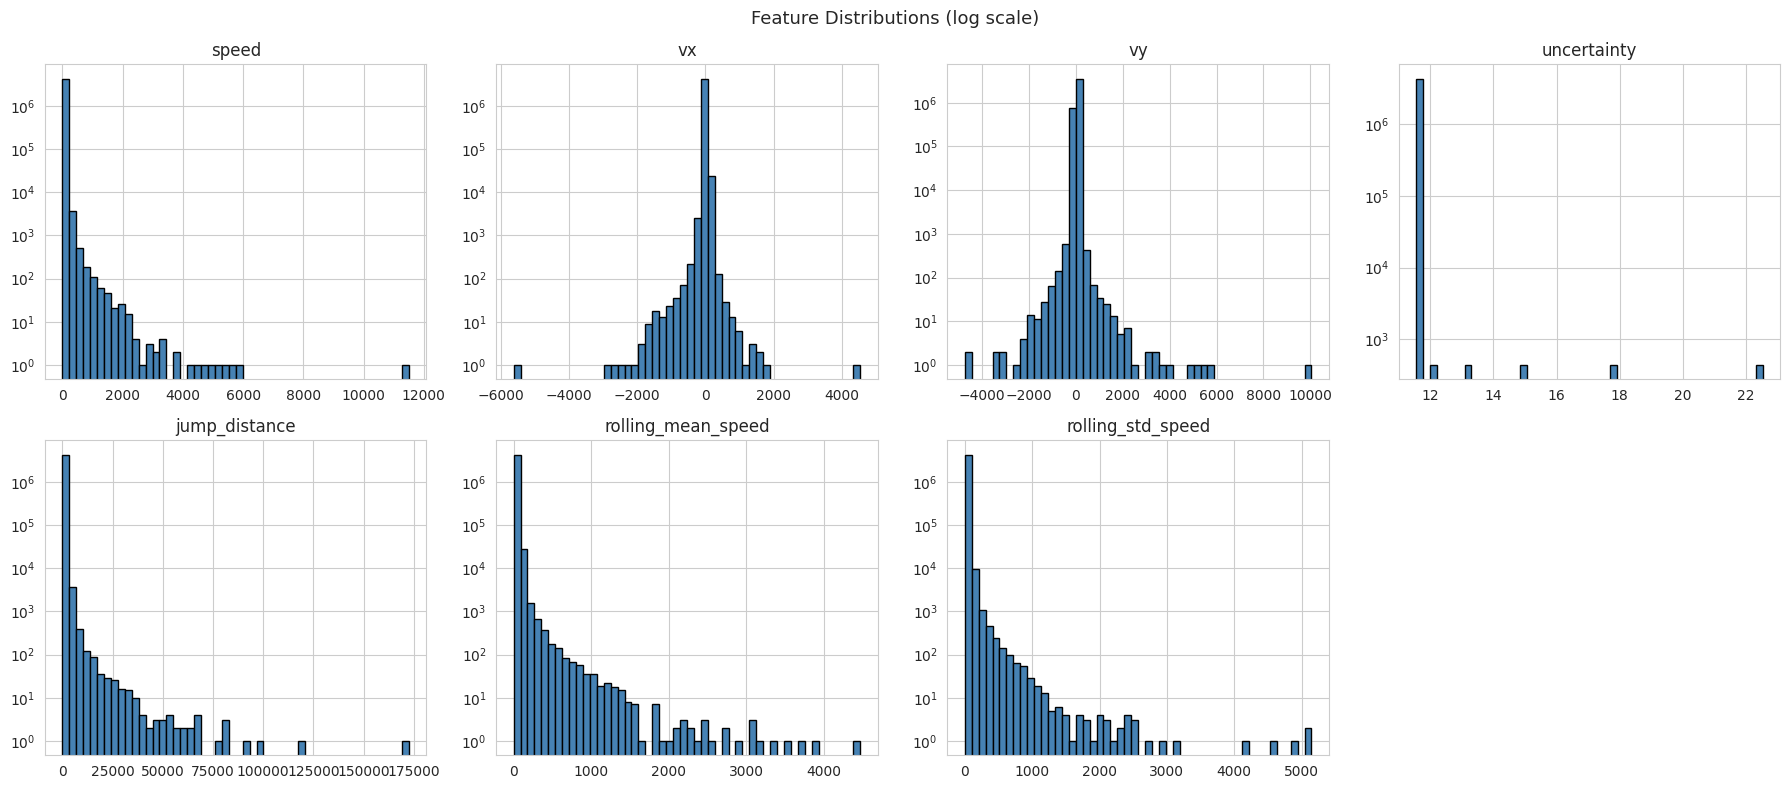

,speed,vx,vy,uncertainty,jump_distance,rolling_mean_speed,rolling_std_speed
count,4.311098e+06,4.311098e+06,4.311098e+06,4.311098e+06,4.311098e+06,4.311098e+06,4.311098e+06
mean,1.089980e+01,-4.926616e-03,1.666560e-03,1.155490e+01,1.500875e+02,1.089962e+01,5.356324e+00
std,2.546937e+01,1.716879e+01,2.174230e+01,1.341781e-01,3.635448e+02,1.962464e+01,1.734284e+01
min,0.000000e+00,-5.619934e+03,-4.734827e+03,1.155254e+01,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.887274e+00,-3.581226e+00,-2.526927e+00,1.155254e+01,3.261753e+01,3.724957e+00,1.010481e+00
50%,6.302837e+00,3.795683e-04,6.476940e-02,1.155254e+01,9.636698e+01,6.840830e+00,1.902205e+00
75%,1.127812e+01,3.359001e+00,3.452962e+00,1.155254e+01,1.776007e+02,1.193562e+01,3.622049e+00
max,1.151308e+04,4.541626e+03,1.004825e+04,2.252272e+01,1.726669e+05,4.471348e+03,5.146486e+03


In [8]:
all_feats = ["speed", "vx", "vy", "uncertainty",
             "jump_distance", "rolling_mean_speed", "rolling_std_speed"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, feat in enumerate(all_feats):
    ax = axes[i // 4, i % 4]
    feat_df[feat].hist(bins=50, ax=ax, color="steelblue", edgecolor="black")
    ax.set_title(feat)
    ax.set_yscale("log")

axes[1, 3].axis("off")
plt.suptitle("Feature Distributions (log scale)", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

feat_df[all_feats].describe()

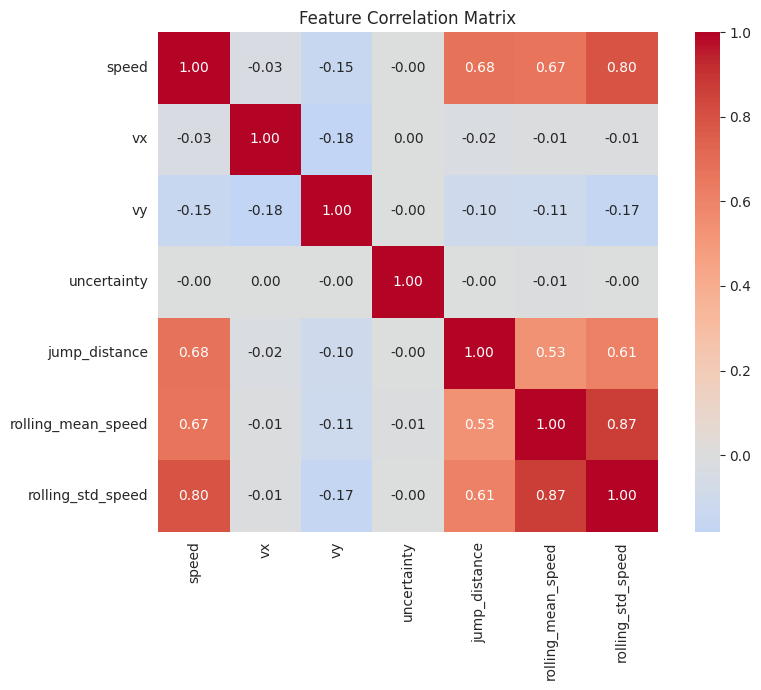

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(feat_df[all_feats].corr(), annot=True, cmap="coolwarm",
            fmt=".2f", center=0, square=True)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig("/kaggle/working/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA findings

**Extreme outliers confirm documented GPS noise**
- Max speed ~11,500 m/s (~41,000 km/h) — physically impossible
- Max jump distance ~172 km in a single 15-second interval
- Median speed 6.3 m/s (~23 km/h) and median jump 96 m are entirely realistic

This matches the ECML/PKDD 2015 challenge documentation, which notes that many GPS points
in this dataset fall outside the road network and require noise correction.

**`uncertainty` is dropped from the model**
Std = 0.13 across 4.3M rows and correlation ~0.00 with every other feature. The Kalman
filter converges to the same steady-state covariance for every taxi, so this column
carries no discriminative information.

**Final feature set: 6 features.**

In [10]:
features = ["speed", "vx", "vy", "jump_distance",
            "rolling_mean_speed", "rolling_std_speed"]

print(f"Model features ({len(features)}): {features}")

Model features (6): ['speed', 'vx', 'vy', 'jump_distance', 'rolling_mean_speed', 'rolling_std_speed']


## 7. Isolation Forest

Unsupervised outlier detection. The algorithm builds random trees that recursively split
the feature space; anomalies require fewer splits to isolate because they sit in sparse
regions. No labels are required.

`contamination=0.03` — the expected anomaly rate, chosen from the EDA distributions.

In [11]:
X = feat_df[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

feat_df["iso_pred"]    = iso.fit_predict(X_scaled)
feat_df["iso_anomaly"] = feat_df["iso_pred"] == -1
feat_df["iso_score"]   = iso.score_samples(X_scaled)

n_anom = feat_df["iso_anomaly"].sum()
print(f"Anomalies detected: {n_anom:,} ({feat_df['iso_anomaly'].mean()*100:.2f}%)")

Anomalies detected: 129,333 (3.00%)


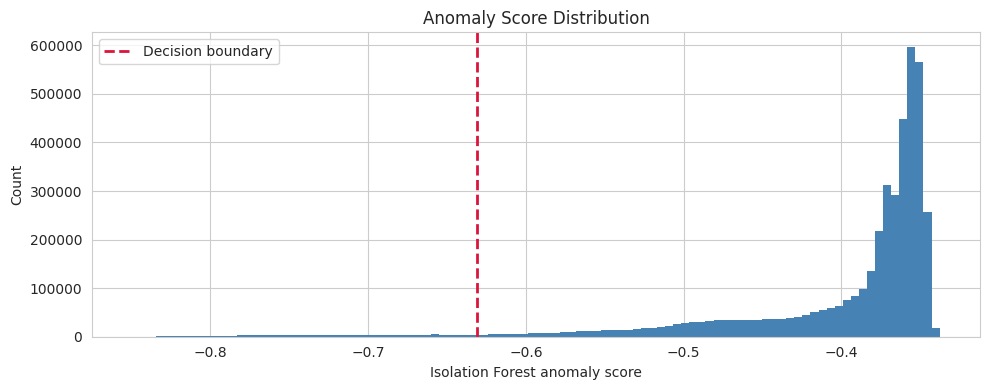

In [12]:
plt.figure(figsize=(10, 4))
plt.hist(feat_df["iso_score"], bins=100, color="steelblue", edgecolor="none")
plt.axvline(feat_df[feat_df["iso_anomaly"]]["iso_score"].max(),
            color="crimson", linestyle="--", linewidth=2, label="Decision boundary")
plt.xlabel("Isolation Forest anomaly score")
plt.ylabel("Count")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/anomaly_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Comparison vs Rule-Based Detector

The production detector uses fixed thresholds, tuned earlier via an F1 sweep on synthetic
anomaly injection:

- `speed > 80 m/s` -> speed anomaly
- `jump_distance > 800 m` -> position jump

No manually labelled ground truth exists for this dataset, so the rule-based output is used
as a **pseudo ground truth** reference. Metrics measure agreement between the two methods,
not absolute correctness.

In [13]:
SPEED_THRESHOLD = 80.0
JUMP_THRESHOLD  = 800.0

feat_df["rule_anomaly"] = (
    (feat_df["speed"] > SPEED_THRESHOLD) |
    (feat_df["jump_distance"] > JUMP_THRESHOLD)
)

print(f"Rule-based anomalies:      {feat_df['rule_anomaly'].sum():,} "
      f"({feat_df['rule_anomaly'].mean()*100:.2f}%)")
print(f"Isolation Forest anomalies: {feat_df['iso_anomaly'].sum():,} "
      f"({feat_df['iso_anomaly'].mean()*100:.2f}%)")

both      = ((feat_df["rule_anomaly"])  & (feat_df["iso_anomaly"])).sum()
only_rule = ((feat_df["rule_anomaly"])  & (~feat_df["iso_anomaly"])).sum()
only_iso  = ((~feat_df["rule_anomaly"]) & (feat_df["iso_anomaly"])).sum()
neither   = ((~feat_df["rule_anomaly"]) & (~feat_df["iso_anomaly"])).sum()

print("\nAgreement matrix:")
print(f"  Both flagged:          {both:,}")
print(f"  Only rule-based:       {only_rule:,}")
print(f"  Only Isolation Forest: {only_iso:,}")
print(f"  Neither:               {neither:,}")
print(f"\nRule-based anomalies also caught by IF: {both/feat_df['rule_anomaly'].sum()*100:.1f}%")

Rule-based anomalies:      81,424 (1.89%)
Isolation Forest anomalies: 129,333 (3.00%)

Agreement matrix:
  Both flagged:          78,195
  Only rule-based:       3,229
  Only Isolation Forest: 51,138
  Neither:               4,178,536

Rule-based anomalies also caught by IF: 96.0%


Isolation Forest vs rule-based (full dataset, in-sample)

              precision    recall  f1-score   support

      Normal      0.999     0.988     0.994   4229674
     Anomaly      0.605     0.960     0.742     81424

    accuracy                          0.987   4311098
   macro avg      0.802     0.974     0.868   4311098
weighted avg      0.992     0.987     0.989   4311098



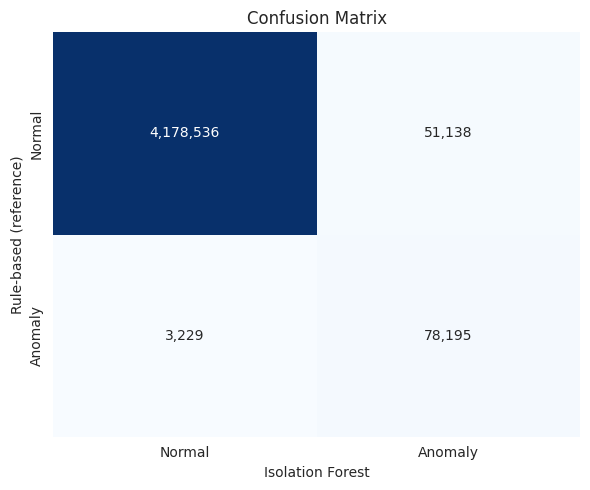

In [14]:
y_true = feat_df["rule_anomaly"].astype(int)
y_pred = feat_df["iso_anomaly"].astype(int)

print("Isolation Forest vs rule-based (full dataset, in-sample)\n")
print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"], digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Normal", "Anomaly"],
            yticklabels=["Normal", "Anomaly"])
plt.xlabel("Isolation Forest")
plt.ylabel("Rule-based (reference)")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Cross-Validation

5-fold **GroupKFold, grouped by taxi**. Consecutive pings from the same vehicle are highly
correlated — random row-level splitting would leak information between folds and inflate
the metrics. Grouping by taxi guarantees every fold is evaluated on vehicles the model has
never seen.

The scaler is fitted on the training fold only and applied to the test fold, so no test
statistics leak into preprocessing.

In [15]:
gkf = GroupKFold(n_splits=5)

X_all  = feat_df[features].fillna(0).values
groups = feat_df["taxi_id"].values

results = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_all, groups=groups), 1):
    X_train, X_test = X_all[train_idx], X_all[test_idx]

    fold_scaler = StandardScaler()
    X_train_scaled = fold_scaler.fit_transform(X_train)
    X_test_scaled  = fold_scaler.transform(X_test)

    fold_iso = IsolationForest(contamination=0.03, n_estimators=100,
                               random_state=42, n_jobs=-1)
    fold_iso.fit(X_train_scaled)

    y_pred_fold = fold_iso.predict(X_test_scaled) == -1

    test_data = feat_df.iloc[test_idx]
    y_rule_fold = ((test_data["speed"] > SPEED_THRESHOLD) |
                   (test_data["jump_distance"] > JUMP_THRESHOLD))

    results.append({
        "fold": fold,
        "train_taxis": len(np.unique(groups[train_idx])),
        "test_taxis": len(np.unique(groups[test_idx])),
        "test_pings": len(test_idx),
        "anomaly_rate_%": round(y_pred_fold.mean() * 100, 2),
        "precision": precision_score(y_rule_fold, y_pred_fold),
        "recall": recall_score(y_rule_fold, y_pred_fold),
        "f1": f1_score(y_rule_fold, y_pred_fold)
    })

    print(f"Fold {fold}: {len(test_idx):>9,} pings | "
          f"{results[-1]['test_taxis']:>3} taxis | "
          f"P={results[-1]['precision']:.3f} "
          f"R={results[-1]['recall']:.3f} "
          f"F1={results[-1]['f1']:.3f}")

cv_df = pd.DataFrame(results)
cv_df.to_csv("/kaggle/working/cv_results.csv", index=False)

print("\n" + "=" * 70)
print("CROSS-VALIDATION SUMMARY (5-fold, grouped by taxi)")
print("=" * 70)
print(cv_df.to_string(index=False))
print(f"\nMean F1:        {cv_df['f1'].mean():.3f} +/- {cv_df['f1'].std():.3f}")
print(f"Mean Precision: {cv_df['precision'].mean():.3f} +/- {cv_df['precision'].std():.3f}")
print(f"Mean Recall:    {cv_df['recall'].mean():.3f} +/- {cv_df['recall'].std():.3f}")

Fold 1:   862,343 pings |  87 taxis | P=0.601 R=0.954 F1=0.737
Fold 2:   862,380 pings |  87 taxis | P=0.601 R=0.958 F1=0.739
Fold 3:   862,116 pings |  90 taxis | P=0.597 R=0.953 F1=0.734
Fold 4:   862,381 pings |  88 taxis | P=0.604 R=0.956 F1=0.740
Fold 5:   861,878 pings |  91 taxis | P=0.611 R=0.968 F1=0.749

CROSS-VALIDATION SUMMARY (5-fold, grouped by taxi)
 fold  train_taxis  test_taxis  test_pings  anomaly_rate_%  precision   recall       f1
    1          356          87      862343            2.95   0.600858 0.953555 0.737193
    2          356          87      862380            3.05   0.601361 0.957925 0.738875
    3          353          90      862116            3.18   0.597232 0.953205 0.734354
    4          355          88      862381            2.91   0.604060 0.956453 0.740468
    5          352          91      861878            2.92   0.610804 0.968220 0.749061

Mean F1:        0.740 +/- 0.006
Mean Precision: 0.603 +/- 0.005
Mean Recall:    0.958 +/- 0.006


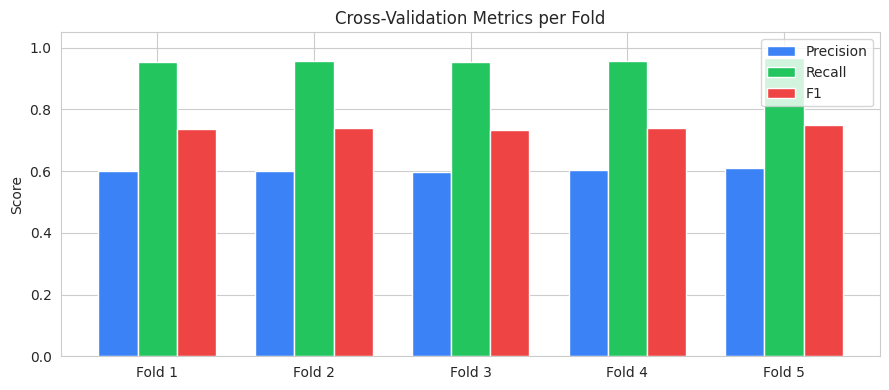

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(cv_df))
w = 0.25

ax.bar(x - w, cv_df["precision"], w, label="Precision", color="#3b82f6")
ax.bar(x,     cv_df["recall"],    w, label="Recall",    color="#22c55e")
ax.bar(x + w, cv_df["f1"],        w, label="F1",        color="#ef4444")

ax.set_xticks(x)
ax.set_xticklabels([f"Fold {i}" for i in cv_df["fold"]])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Cross-Validation Metrics per Fold")
ax.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/cv_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. What Does Isolation Forest Catch That Rules Miss?

The most interesting group is the pings flagged by Isolation Forest but not by any threshold.
These are cases where no single feature is extreme, but the *combination* is unusual —
exactly what one-dimensional rules cannot express.

In [17]:
only_iso_df = feat_df[(~feat_df["rule_anomaly"]) & (feat_df["iso_anomaly"])]
normal_df   = feat_df[(~feat_df["rule_anomaly"]) & (~feat_df["iso_anomaly"])]

print(f"Flagged by Isolation Forest only: {len(only_iso_df):,}\n")

comparison_stats = pd.DataFrame({
    "IF-only anomaly (mean)": only_iso_df[features].mean(),
    "Normal (mean)":          normal_df[features].mean(),
    "Ratio":                  only_iso_df[features].mean() / normal_df[features].mean()
})
comparison_stats.round(2)

Flagged by Isolation Forest only: 51,138



,IF-only anomaly (mean),Normal (mean),Ratio
speed,46.80,8.32,5.62
vx,5.58,-0.34,-16.25
vy,-5.87,0.74,-7.98
jump_distance,299.51,124.89,2.40
rolling_mean_speed,71.72,9.09,7.89
rolling_std_speed,53.43,3.51,15.21


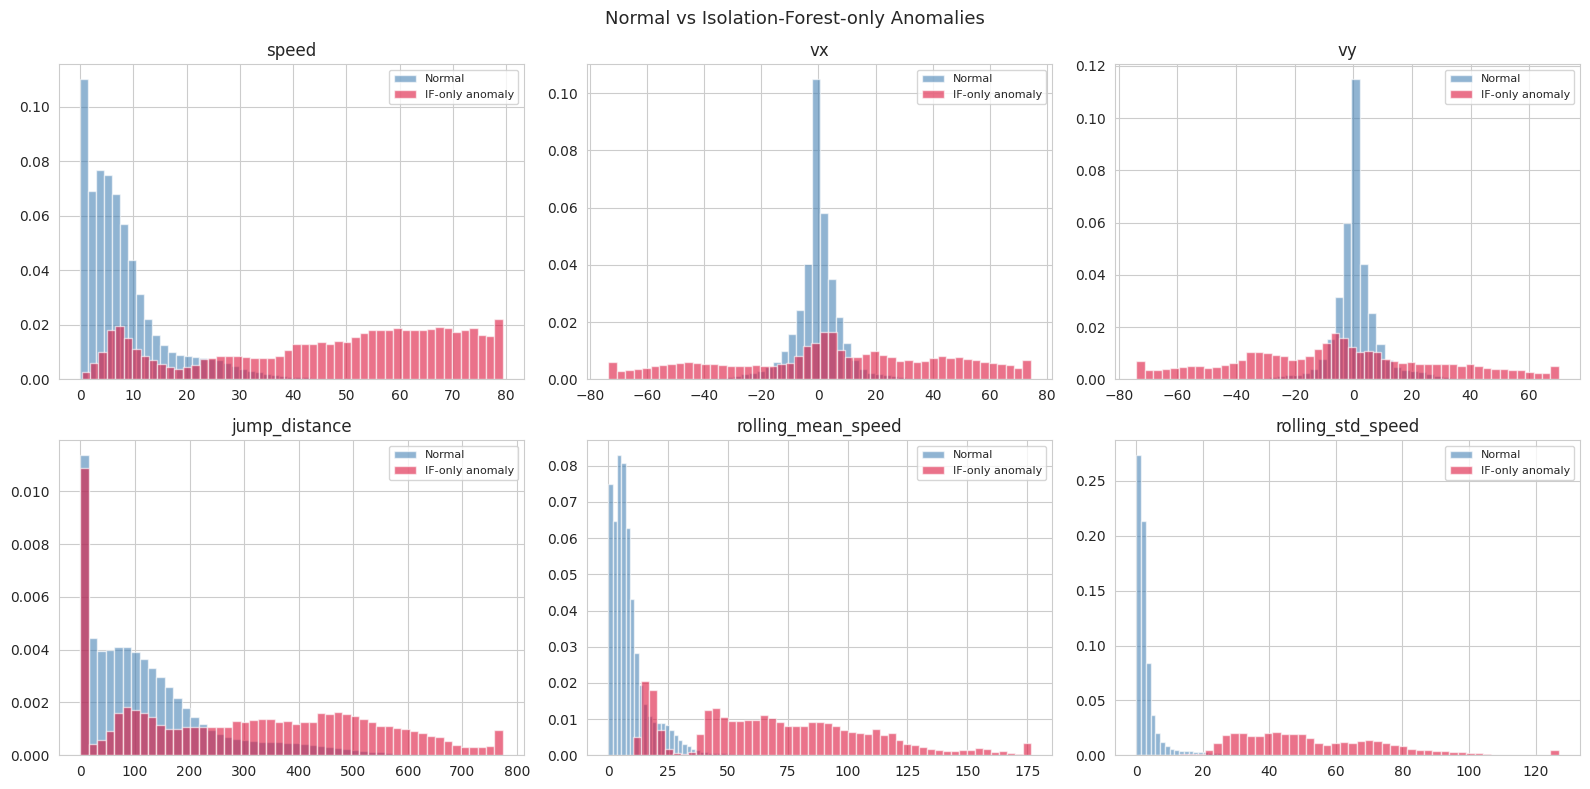

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, feat in enumerate(features):
    ax = axes[i // 3, i % 3]
    hi = max(normal_df[feat].quantile(0.99), only_iso_df[feat].quantile(0.99))
    lo = min(normal_df[feat].quantile(0.01), only_iso_df[feat].quantile(0.01))

    ax.hist(normal_df[feat].clip(lo, hi), bins=50, alpha=0.6,
            label="Normal", color="steelblue", density=True)
    ax.hist(only_iso_df[feat].clip(lo, hi), bins=50, alpha=0.6,
            label="IF-only anomaly", color="crimson", density=True)
    ax.set_title(feat)
    ax.legend(fontsize=8)

plt.suptitle("Normal vs Isolation-Forest-only Anomalies", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/if_only_anomalies.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Feature Importance

Permutation importance: each feature is shuffled in turn and the mean anomaly score shift is measured. Larger shift = feature contributes more to the decision.

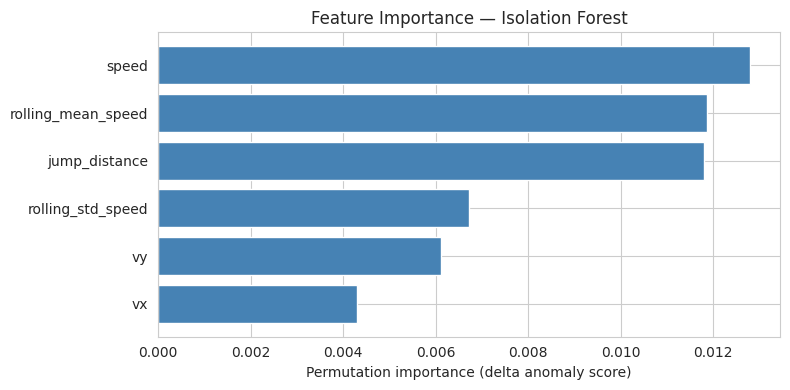

,feature,importance
0,speed,0.012806
1,rolling_mean_speed,0.011870
2,jump_distance,0.011793
3,rolling_std_speed,0.006723
4,vy,0.006105
5,vx,0.004292


In [19]:
baseline = iso.score_samples(X_scaled).mean()
importances = {}

rng = np.random.default_rng(42)
for i, feat in enumerate(features):
    X_shuffled = X_scaled.copy()
    rng.shuffle(X_shuffled[:, i])
    importances[feat] = abs(baseline - iso.score_samples(X_shuffled).mean())

imp_df = (pd.DataFrame(importances.items(), columns=["feature", "importance"])
            .sort_values("importance", ascending=False)
            .reset_index(drop=True))

plt.figure(figsize=(8, 4))
plt.barh(imp_df["feature"], imp_df["importance"], color="steelblue")
plt.xlabel("Permutation importance (delta anomaly score)")
plt.title("Feature Importance — Isolation Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("/kaggle/working/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

imp_df

## 12. Per-Taxi Anomaly Analysis

Top 15 most anomalous taxis (Isolation Forest):
 taxi_id  pings  iso_anomalies  iso_rate_%  rule_rate_%  mean_speed  mean_jump
20000276  10778            667        6.19         3.78   15.750976 216.555254
20000657   9540            577        6.05         3.62   16.622373 221.222040
20000231   6825            404        5.92         3.71   15.030459 201.595393
20000477   9917            583        5.88         3.46   16.818821 221.925358
20000534  14957            846        5.66         3.42   17.892588 245.878484
20000263   8981            502        5.59         3.60   16.800247 224.771756
20000334  10464            553        5.28         3.28   16.715694 227.146509
20000273   6893            355        5.15         3.12   15.674554 208.039194
20000199  10455            527        5.04         3.30   15.426012 215.218025
20000525   9054            456        5.04         3.17   13.924089 189.883562
20000003   7771            391        5.03         2.97   15.658910 204.977069
2000

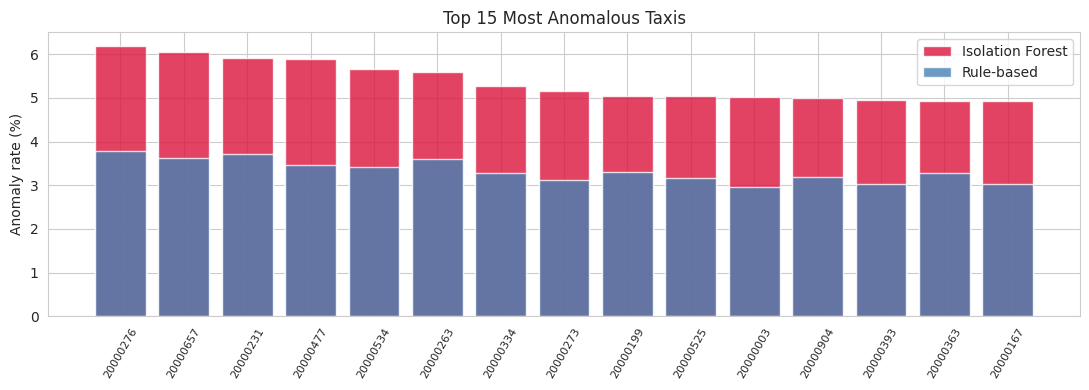

In [20]:
taxi_stats = feat_df.groupby("taxi_id").agg(
    pings=("speed", "size"),
    iso_anomalies=("iso_anomaly", "sum"),
    rule_anomalies=("rule_anomaly", "sum"),
    mean_speed=("speed", "mean"),
    mean_jump=("jump_distance", "mean")
).reset_index()

taxi_stats["iso_rate_%"]  = (taxi_stats["iso_anomalies"] / taxi_stats["pings"] * 100).round(2)
taxi_stats["rule_rate_%"] = (taxi_stats["rule_anomalies"] / taxi_stats["pings"] * 100).round(2)

worst = taxi_stats.sort_values("iso_rate_%", ascending=False).head(15)
print("Top 15 most anomalous taxis (Isolation Forest):")
print(worst[["taxi_id", "pings", "iso_anomalies", "iso_rate_%",
             "rule_rate_%", "mean_speed", "mean_jump"]].to_string(index=False))

plt.figure(figsize=(11, 4))
plt.bar(range(len(worst)), worst["iso_rate_%"], color="crimson", alpha=0.8, label="Isolation Forest")
plt.bar(range(len(worst)), worst["rule_rate_%"], color="steelblue", alpha=0.8, label="Rule-based")
plt.xticks(range(len(worst)), worst["taxi_id"].astype(str), rotation=60, fontsize=8)
plt.ylabel("Anomaly rate (%)")
plt.title("Top 15 Most Anomalous Taxis")
plt.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/worst_taxis.png", dpi=150, bbox_inches="tight")
plt.show()

taxi_stats.to_csv("/kaggle/working/taxi_anomaly_stats.csv", index=False)

In [21]:
print(taxi_stats[["mean_speed", "mean_jump", "iso_rate_%", "rule_rate_%"]].corr())

             mean_speed  mean_jump  iso_rate_%  rule_rate_%
mean_speed     1.000000   0.991878    0.872682     0.878606
mean_jump      0.991878   1.000000    0.842547     0.859416
iso_rate_%     0.872682   0.842547    1.000000     0.985582
rule_rate_%    0.878606   0.859416    0.985582     1.000000


## 13. Diagnosing the Speed Confound

The per-taxi analysis revealed a problem: a vehicle's anomaly rate correlates strongly
with its average speed (r = 0.87). This means both detectors are largely surfacing
**fast-driving vehicles** rather than **faulty GPS hardware**.

The mechanism is arithmetic. `jump_distance ≈ speed × 15s`, so `mean_speed` and
`mean_jump` are 0.992 correlated. A vehicle that habitually drives fast produces large
jump distances by definition, crossing absolute thresholds more often regardless of
sensor quality.

**Hypothesis:** replacing absolute features with per-vehicle normalised features should
reduce this confound. Instead of asking *"is this ping fast?"*, the model asks *"is this
ping fast **for this vehicle**?"*

| Absolute feature | Normalised equivalent | Interpretation |
|---|---|---|
| `speed` | `speed_z` | standard deviations from this taxi's own mean |
| `jump_distance` | `jump_z` | standard deviations from this taxi's own mean |
| — | `speed_ratio` | current speed ÷ recent 5-ping average |
| `rolling_std_speed` | `rolling_std_ratio` | variance relative to this taxi's typical variance |

`rolling_std_ratio` is included because raw variance is itself speed-dependent — leaving
it unnormalised would reintroduce the confound through the back door.

In [22]:
# ── Per-vehicle normalised features ────────────────────────────────────────
# Absolute features conflate "fast vehicle" with "faulty sensor" because
# jump_distance ≈ speed × 15s (r = 0.992). Normalising each ping against its
# own vehicle's baseline asks "unusual for THIS taxi?" rather than
# "unusual for the fleet?".

eps = 1e-6

feat_df["speed_z"] = feat_df.groupby("taxi_id")["speed"].transform(
    lambda s: (s - s.mean()) / (s.std() + eps)
)
feat_df["jump_z"] = feat_df.groupby("taxi_id")["jump_distance"].transform(
    lambda s: (s - s.mean()) / (s.std() + eps)
)
feat_df["speed_ratio"] = feat_df["speed"] / (feat_df["rolling_mean_speed"] + eps)
feat_df["rolling_std_ratio"] = feat_df["rolling_std_speed"] / (
    feat_df.groupby("taxi_id")["rolling_std_speed"].transform("mean") + eps
)

features_norm = ["speed_z", "jump_z", "speed_ratio",
                 "rolling_std_ratio", "vx", "vy"]

X_norm = feat_df[features_norm].replace([np.inf, -np.inf], np.nan).fillna(0)
scaler_norm = StandardScaler()
X_norm_scaled = scaler_norm.fit_transform(X_norm)

iso_norm = IsolationForest(contamination=0.03, n_estimators=100,
                           random_state=42, n_jobs=-1)
feat_df["iso_norm_anomaly"] = iso_norm.fit_predict(X_norm_scaled) == -1

print(f"Normalised-model anomalies: {feat_df['iso_norm_anomaly'].sum():,} "
      f"({feat_df['iso_norm_anomaly'].mean()*100:.2f}%)")

Normalised-model anomalies: 129,333 (3.00%)


Correlation between a taxi's mean speed and its anomaly rate
(closer to 0 = less confounded by driving profile)

  Rule-based:            r = +0.879
  IF, absolute features: r = +0.873
  IF, normalised:        r = +0.477

  Confound reduction: 45.4%


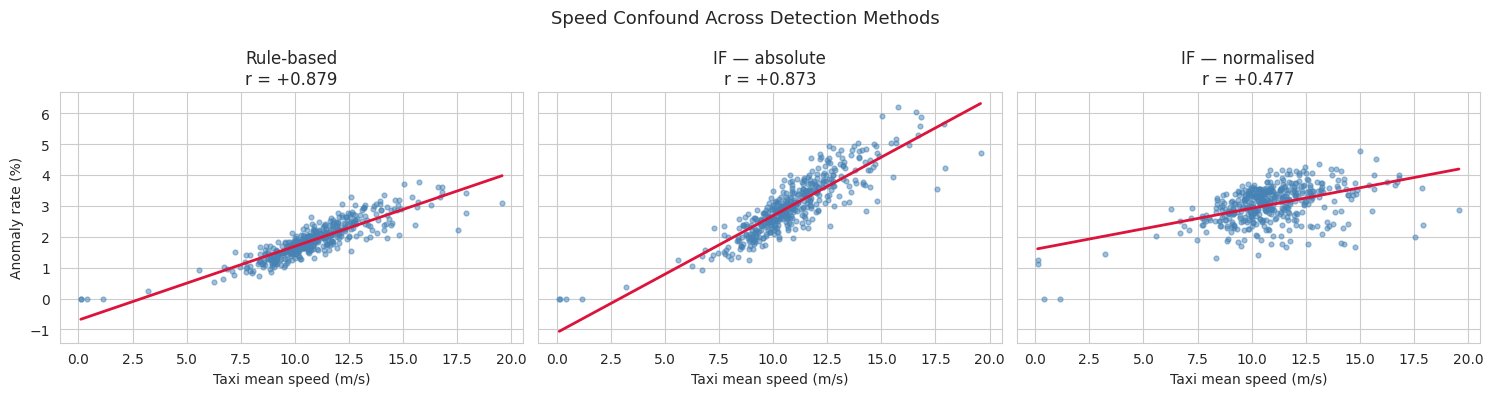

In [23]:
# ── Did normalisation remove the speed confound? ───────────────────────────
taxi_cmp = feat_df.groupby("taxi_id").agg(
    pings=("speed", "size"),
    mean_speed=("speed", "mean"),
    rate_abs=("iso_anomaly", "mean"),
    rate_norm=("iso_norm_anomaly", "mean"),
    rate_rule=("rule_anomaly", "mean")
).reset_index()

for c in ["rate_abs", "rate_norm", "rate_rule"]:
    taxi_cmp[c] *= 100

r_abs  = taxi_cmp[["mean_speed", "rate_abs"]].corr().iloc[0, 1]
r_norm = taxi_cmp[["mean_speed", "rate_norm"]].corr().iloc[0, 1]
r_rule = taxi_cmp[["mean_speed", "rate_rule"]].corr().iloc[0, 1]

print("Correlation between a taxi's mean speed and its anomaly rate")
print("(closer to 0 = less confounded by driving profile)\n")
print(f"  Rule-based:            r = {r_rule:+.3f}")
print(f"  IF, absolute features: r = {r_abs:+.3f}")
print(f"  IF, normalised:        r = {r_norm:+.3f}")
print(f"\n  Confound reduction: {(1 - abs(r_norm)/abs(r_abs))*100:.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (col, r, title) in zip(axes, [
        ("rate_rule", r_rule, "Rule-based"),
        ("rate_abs",  r_abs,  "IF — absolute"),
        ("rate_norm", r_norm, "IF — normalised")]):
    ax.scatter(taxi_cmp["mean_speed"], taxi_cmp[col], s=12, alpha=0.5, color="steelblue")
    z = np.polyfit(taxi_cmp["mean_speed"], taxi_cmp[col], 1)
    xs = np.linspace(taxi_cmp["mean_speed"].min(), taxi_cmp["mean_speed"].max(), 50)
    ax.plot(xs, np.poly1d(z)(xs), color="crimson", lw=2)
    ax.set_title(f"{title}\nr = {r:+.3f}")
    ax.set_xlabel("Taxi mean speed (m/s)")
axes[0].set_ylabel("Anomaly rate (%)")
plt.suptitle("Speed Confound Across Detection Methods", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/confound_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

taxi_cmp.to_csv("/kaggle/working/taxi_confound_comparison.csv", index=False)

In [24]:
overlap = (feat_df["iso_anomaly"] & feat_df["iso_norm_anomaly"]).sum()
only_abs = (feat_df["iso_anomaly"] & ~feat_df["iso_norm_anomaly"]).sum()
only_norm = (~feat_df["iso_anomaly"] & feat_df["iso_norm_anomaly"]).sum()

print(f"Flagged by both models:      {overlap:,}")
print(f"Only absolute model:         {only_abs:,}")
print(f"Only normalised model:       {only_norm:,}")
print(f"Overlap: {overlap/129333*100:.1f}%")

# what do the normalised-only detections look like?
norm_only = feat_df[~feat_df["iso_anomaly"] & feat_df["iso_norm_anomaly"]]
print("\nPings caught ONLY by the normalised model:")
print(norm_only[["speed", "jump_distance", "rolling_mean_speed", 
                 "speed_z", "speed_ratio"]].describe().T[["mean", "50%", "max"]].round(2))

Flagged by both models:      106,853
Only absolute model:         22,480
Only normalised model:       22,480
Overlap: 82.6%

Pings caught ONLY by the normalised model:
                      mean    50%      max
speed                45.20  45.45    74.59
jump_distance       218.05   0.00  1740.93
rolling_mean_speed   15.98  14.05    89.17
speed_z               2.04   1.99     8.65
speed_ratio           3.33   3.51     4.99


In [25]:
abs_only = feat_df[feat_df["iso_anomaly"] & ~feat_df["iso_norm_anomaly"]]
norm_only = feat_df[~feat_df["iso_anomaly"] & feat_df["iso_norm_anomaly"]]

trade = pd.DataFrame({
    "Caught only by ABSOLUTE": abs_only[["speed", "speed_ratio", "rolling_mean_speed"]].median(),
    "Caught only by NORMALISED": norm_only[["speed", "speed_ratio", "rolling_mean_speed"]].median()
}).round(2)

print(trade)
print(f"\nAbsolute-only  — median speed {abs_only['speed'].median():.1f} m/s, "
      f"median ratio {abs_only['speed_ratio'].median():.2f}x")
print(f"Normalised-only — median speed {norm_only['speed'].median():.1f} m/s, "
      f"median ratio {norm_only['speed_ratio'].median():.2f}x")
print(f"\nPings above 80 m/s rule threshold in normalised-only group: "
      f"{(norm_only['speed'] > 80).sum()}")
print(f"Pings above 800m jump threshold in normalised-only group: "
      f"{(norm_only['jump_distance'] > 800).sum()}")

                    Caught only by ABSOLUTE  Caught only by NORMALISED
speed                                 30.66                      45.45
speed_ratio                            0.30                       3.51
rolling_mean_speed                    74.09                      14.05

Absolute-only  — median speed 30.7 m/s, median ratio 0.30x
Normalised-only — median speed 45.5 m/s, median ratio 3.51x

Pings above 80 m/s rule threshold in normalised-only group: 0
Pings above 800m jump threshold in normalised-only group: 830


### Result: the normalisation trade

`contamination=0.03` fixes the total detection count, so the two models flagged an
identical 129,333 pings with 82.6% overlap. The 22,480-ping symmetric difference shows
exactly what changed:

| | Absolute-only | Normalised-only |
|---|---|---|
| Median speed | 30.7 m/s | 45.5 m/s |
| Median recent average | 74.1 m/s | 14.1 m/s |
| **Median speed_ratio** | **0.30×** | **3.51×** |
| Above 80 m/s rule threshold | — | 0 |
| Above 800 m jump threshold | — | 830 (3.7%) |

The absolute model was flagging vehicles at 30 m/s that had just been travelling at 74 m/s
— **decelerating normally**, at 0.30× their own baseline. These are false alarms produced
by comparing against a fleet median of 6.3 m/s rather than each vehicle's own profile.

The normalised model instead flags vehicles averaging 14 m/s that suddenly read 45 m/s —
**3.51× their own baseline**. A 15-second jump from 50 km/h to 164 km/h is not acceleration;
it is a sensor fault. Critically, **none** of these cross the 80 m/s speed threshold and only
3.7% cross the 800 m jump threshold, so ~96% are undetectable by the rule-based system.

**Confound reduction: r = 0.873 → 0.477 (−45.4%).**

The residual r = 0.477 has two components that cannot be separated without labelled ground
truth. Part is genuine — high-speed driving implies highways, tunnels and overpasses, where
multipath error and poor satellite geometry really do degrade GPS quality. Part is residual
leakage: `vx` and `vy` remain absolute in the normalised feature set and their magnitude
still scales with speed. Normalising the velocity components by vehicle heading variance
would be the next step.

In [26]:
# ── V2: also normalise the velocity components ─────────────────────────────
# vx and vy remained absolute in the first normalised model — their magnitude
# still scales with speed, reintroducing the confound through the back door.

feat_df["vx_z"] = feat_df.groupby("taxi_id")["vx"].transform(
    lambda s: (s - s.mean()) / (s.std() + eps)
)
feat_df["vy_z"] = feat_df.groupby("taxi_id")["vy"].transform(
    lambda s: (s - s.mean()) / (s.std() + eps)
)

features_norm_v2 = ["speed_z", "jump_z", "speed_ratio",
                    "rolling_std_ratio", "vx_z", "vy_z"]

X_v2 = feat_df[features_norm_v2].replace([np.inf, -np.inf], np.nan).fillna(0)
scaler_v2 = StandardScaler()
X_v2_scaled = scaler_v2.fit_transform(X_v2)

iso_v2 = IsolationForest(contamination=0.03, n_estimators=100,
                         random_state=42, n_jobs=-1)
feat_df["iso_v2_anomaly"] = iso_v2.fit_predict(X_v2_scaled) == -1

# recompute the confound
taxi_v2 = feat_df.groupby("taxi_id").agg(
    mean_speed=("speed", "mean"),
    rate_v2=("iso_v2_anomaly", "mean")
).reset_index()
taxi_v2["rate_v2"] *= 100

r_v2 = taxi_v2[["mean_speed", "rate_v2"]].corr().iloc[0, 1]

print("Speed confound across all model variants:\n")
print(f"  Rule-based:                    r = {r_rule:+.3f}")
print(f"  IF, absolute features:         r = {r_abs:+.3f}")
print(f"  IF, normalised (vx/vy raw):    r = {r_norm:+.3f}")
print(f"  IF, normalised (vx/vy scaled): r = {r_v2:+.3f}")
print(f"\n  Total reduction vs absolute: {(1 - abs(r_v2)/abs(r_abs))*100:.1f}%")

Speed confound across all model variants:

  Rule-based:                    r = +0.879
  IF, absolute features:         r = +0.873
  IF, normalised (vx/vy raw):    r = +0.477
  IF, normalised (vx/vy scaled): r = -0.002

  Total reduction vs absolute: 99.8%


In [27]:
v2_only = feat_df[~feat_df["iso_anomaly"] & feat_df["iso_v2_anomaly"]]

print(f"V2 anomalies: {feat_df['iso_v2_anomaly'].sum():,}")
print(f"Overlap with rule-based: "
      f"{(feat_df['iso_v2_anomaly'] & feat_df['rule_anomaly']).sum():,} "
      f"({(feat_df['iso_v2_anomaly'] & feat_df['rule_anomaly']).sum() / feat_df['rule_anomaly'].sum()*100:.1f}% of rule detections)")
print(f"Overlap with normalised v1: "
      f"{(feat_df['iso_v2_anomaly'] & feat_df['iso_norm_anomaly']).sum():,}")

print("\nMedian profile of V2-only detections:")
print(v2_only[["speed", "speed_ratio", "rolling_mean_speed",
               "jump_distance"]].median().round(2))

print(f"\nAnomaly rate spread across taxis:")
print(f"  min  {taxi_v2['rate_v2'].min():.2f}%")
print(f"  max  {taxi_v2['rate_v2'].max():.2f}%")
print(f"  std  {taxi_v2['rate_v2'].std():.2f}")

V2 anomalies: 129,333
Overlap with rule-based: 75,428 (92.6% of rule detections)
Overlap with normalised v1: 123,517

Median profile of V2-only detections:
speed                 44.13
speed_ratio            3.27
rolling_mean_speed    14.67
jump_distance          0.00
dtype: float64

Anomaly rate spread across taxis:
  min  0.00%
  max  5.56%
  std  0.66


## 14. Final Comparison & Model Export

In [29]:
gkf = GroupKFold(n_splits=5)
X_v2_all = feat_df[features_norm_v2].replace([np.inf, -np.inf], np.nan).fillna(0).values
groups = feat_df["taxi_id"].values

results_v2 = []
for fold, (tr, te) in enumerate(gkf.split(X_v2_all, groups=groups), 1):
    sc = StandardScaler()
    m = IsolationForest(contamination=0.03, n_estimators=100,
                        random_state=42, n_jobs=-1)
    m.fit(sc.fit_transform(X_v2_all[tr]))
    pred = m.predict(sc.transform(X_v2_all[te])) == -1

    td = feat_df.iloc[te]
    rule = (td["speed"] > SPEED_THRESHOLD) | (td["jump_distance"] > JUMP_THRESHOLD)

    results_v2.append({
        "fold": fold,
        "precision": precision_score(rule, pred),
        "recall": recall_score(rule, pred),
        "f1": f1_score(rule, pred)
    })
    print(f"Fold {fold}: P={results_v2[-1]['precision']:.3f} "
          f"R={results_v2[-1]['recall']:.3f} F1={results_v2[-1]['f1']:.3f}")

cv_v2 = pd.DataFrame(results_v2)
print(f"\nV2 mean F1: {cv_v2['f1'].mean():.3f} ± {cv_v2['f1'].std():.3f}")
print(f"Absolute model F1 for comparison: {cv_df['f1'].mean():.3f} ± {cv_df['f1'].std():.3f}")
print(f"\nDrop: {cv_df['f1'].mean() - cv_v2['f1'].mean():+.3f}")

Fold 1: P=0.582 R=0.921 F1=0.713
Fold 2: P=0.578 R=0.941 F1=0.716
Fold 3: P=0.613 R=0.903 F1=0.730
Fold 4: P=0.571 R=0.940 F1=0.711
Fold 5: P=0.585 R=0.945 F1=0.723

V2 mean F1: 0.719 ± 0.008
Absolute model F1 for comparison: 0.740 ± 0.006

Drop: +0.021


In [30]:
X_v1_all = feat_df[features_norm].replace([np.inf, -np.inf], np.nan).fillna(0).values

results_v1 = []
for fold, (tr, te) in enumerate(gkf.split(X_v1_all, groups=groups), 1):
    sc = StandardScaler()
    m = IsolationForest(contamination=0.03, n_estimators=100,
                        random_state=42, n_jobs=-1)
    m.fit(sc.fit_transform(X_v1_all[tr]))
    pred = m.predict(sc.transform(X_v1_all[te])) == -1

    td = feat_df.iloc[te]
    rule = (td["speed"] > SPEED_THRESHOLD) | (td["jump_distance"] > JUMP_THRESHOLD)

    results_v1.append({
        "fold": fold,
        "precision": precision_score(rule, pred),
        "recall": recall_score(rule, pred),
        "f1": f1_score(rule, pred)
    })
    print(f"Fold {fold}: P={results_v1[-1]['precision']:.3f} "
          f"R={results_v1[-1]['recall']:.3f} F1={results_v1[-1]['f1']:.3f}")

cv_v1 = pd.DataFrame(results_v1)

print(f"\n{'Model':<32} {'F1':<18} {'Confound r'}")
print("-" * 62)
print(f"{'IF — absolute':<32} {cv_df['f1'].mean():.3f} ± {cv_df['f1'].std():.3f}      {r_abs:+.3f}")
print(f"{'IF — normalised v1':<32} {cv_v1['f1'].mean():.3f} ± {cv_v1['f1'].std():.3f}      {r_norm:+.3f}")
print(f"{'IF — normalised v2 (final)':<32} {cv_v2['f1'].mean():.3f} ± {cv_v2['f1'].std():.3f}      {r_v2:+.3f}")

Fold 1: P=0.594 R=0.944 F1=0.729
Fold 2: P=0.588 R=0.949 F1=0.726
Fold 3: P=0.617 R=0.931 F1=0.742
Fold 4: P=0.583 R=0.953 F1=0.723
Fold 5: P=0.597 R=0.956 F1=0.735

Model                            F1                 Confound r
--------------------------------------------------------------
IF — absolute                    0.740 ± 0.006      +0.873
IF — normalised v1               0.731 ± 0.008      +0.477
IF — normalised v2 (final)       0.719 ± 0.008      -0.002


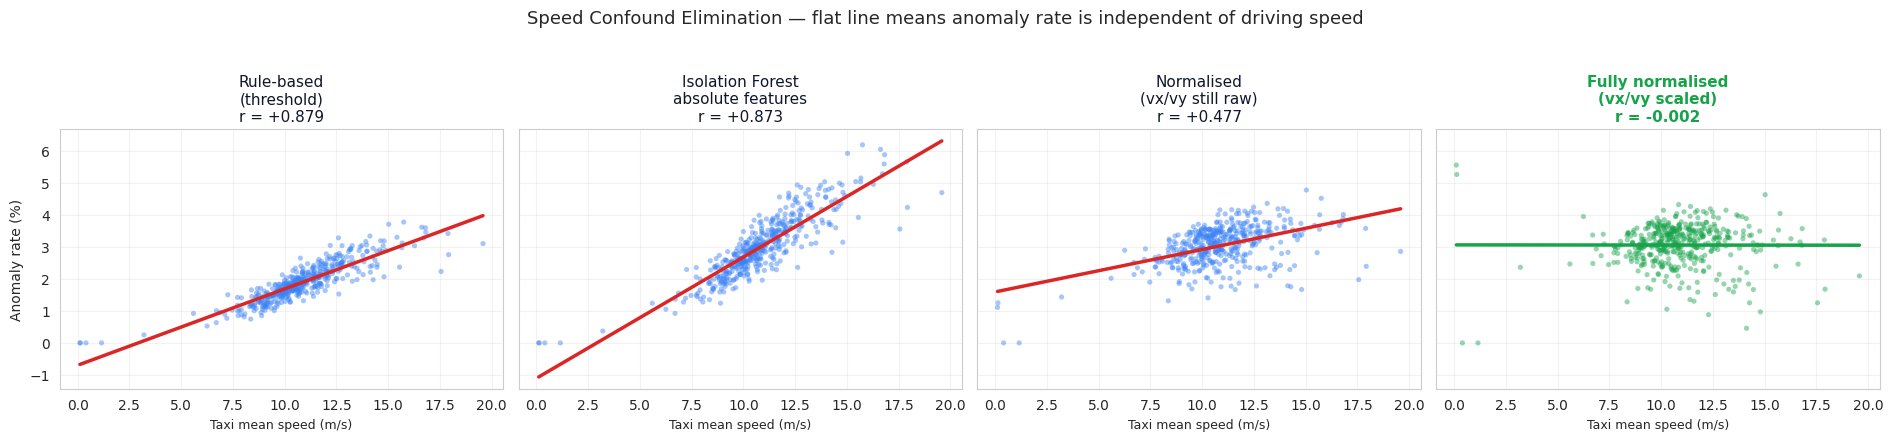

Progression:  +0.879  →  +0.873  →  +0.477  →  -0.002


In [33]:
# ── Confound progression across all four detection variants ────────────────
taxi_all = feat_df.groupby("taxi_id").agg(
    mean_speed=("speed", "mean"),
    rate_rule=("rule_anomaly", "mean"),
    rate_abs=("iso_anomaly", "mean"),
    rate_norm=("iso_norm_anomaly", "mean"),
    rate_v2=("iso_v2_anomaly", "mean")
).reset_index()

for c in ["rate_rule", "rate_abs", "rate_norm", "rate_v2"]:
    taxi_all[c] *= 100

panels = [
    ("rate_rule", r_rule,  "Rule-based\n(threshold)"),
    ("rate_abs",  r_abs,   "Isolation Forest\nabsolute features"),
    ("rate_norm", r_norm,  "Normalised\n(vx/vy still raw)"),
    ("rate_v2",   r_v2,    "Fully normalised\n(vx/vy scaled)")
]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), sharey=True)

for ax, (col, r, title) in zip(axes, panels):
    good = abs(r) < 0.2
    ax.scatter(taxi_all["mean_speed"], taxi_all[col],
               s=14, alpha=0.45,
               color="#16a34a" if good else "#3b82f6",
               edgecolors="none")
    z = np.polyfit(taxi_all["mean_speed"], taxi_all[col], 1)
    xs = np.linspace(taxi_all["mean_speed"].min(), taxi_all["mean_speed"].max(), 50)
    ax.plot(xs, np.poly1d(z)(xs),
            color="#16a34a" if good else "#dc2626", lw=2.5)
    ax.set_title(f"{title}\nr = {r:+.3f}", fontsize=11,
                 color="#16a34a" if good else "#0f172a",
                 fontweight="bold" if good else "normal")
    ax.set_xlabel("Taxi mean speed (m/s)", fontsize=9)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Anomaly rate (%)", fontsize=10)
plt.suptitle(
    "Speed Confound Elimination — flat line means anomaly rate is independent of driving speed",
    fontsize=13, y=1.04)
plt.tight_layout()
plt.savefig("/kaggle/working/confound_progression.png", dpi=150, bbox_inches="tight")
plt.show()

print("Progression:  "
      f"{r_rule:+.3f}  →  {r_abs:+.3f}  →  {r_norm:+.3f}  →  {r_v2:+.3f}")

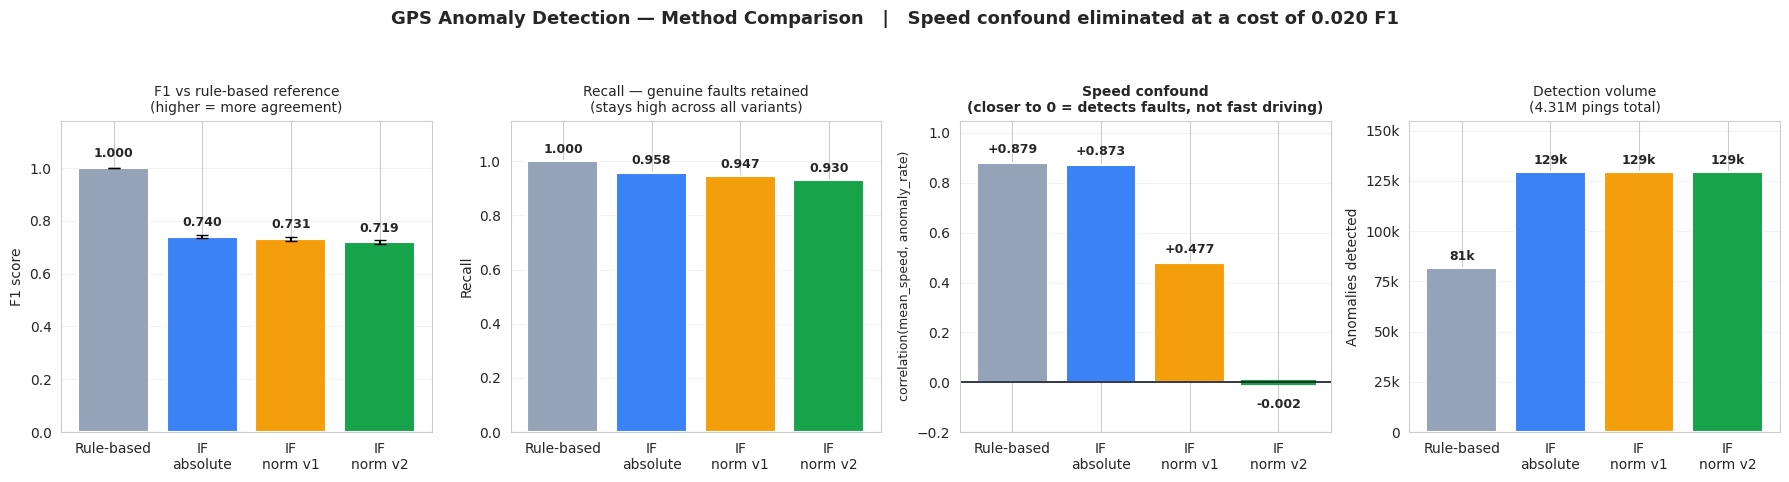

In [34]:
# ── Master comparison figure — final ───────────────────────────────────────
methods = ["Rule-based", "IF\nabsolute", "IF\nnorm v1", "IF\nnorm v2"]
colors  = ["#94a3b8", "#3b82f6", "#f59e0b", "#16a34a"]

f1_vals   = [1.000, cv_df["f1"].mean(), cv_v1["f1"].mean(), cv_v2["f1"].mean()]
f1_errs   = [0, cv_df["f1"].std(), cv_v1["f1"].std(), cv_v2["f1"].std()]
rec_vals  = [1.000, cv_df["recall"].mean(), cv_v1["recall"].mean(), cv_v2["recall"].mean()]
conf_vals = [r_rule, r_abs, r_norm, r_v2]
n_anom    = [int(feat_df["rule_anomaly"].sum()),
             int(feat_df["iso_anomaly"].sum()),
             int(feat_df["iso_norm_anomaly"].sum()),
             int(feat_df["iso_v2_anomaly"].sum())]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

# Panel 1 — F1
ax = axes[0]
ax.bar(methods, f1_vals, yerr=f1_errs, color=colors, capsize=4,
       edgecolor="white", lw=1.5)
for i, v in enumerate(f1_vals):
    ax.text(i, v + 0.04, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 1.18)
ax.set_ylabel("F1 score", fontsize=10)
ax.set_title("F1 vs rule-based reference\n(higher = more agreement)", fontsize=10)
ax.grid(axis="y", alpha=0.25)

# Panel 2 — Recall
ax = axes[1]
ax.bar(methods, rec_vals, color=colors, edgecolor="white", lw=1.5)
for i, v in enumerate(rec_vals):
    ax.text(i, v + 0.03, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 1.15)
ax.set_ylabel("Recall", fontsize=10)
ax.set_title("Recall — genuine faults retained\n(stays high across all variants)", fontsize=10)
ax.grid(axis="y", alpha=0.25)

# Panel 3 — Confound
ax = axes[2]
bars = ax.bar(methods, conf_vals, color=colors, edgecolor="white", lw=1.5)
bars[3].set_edgecolor("#16a34a")
bars[3].set_linewidth(3)
for i, v in enumerate(conf_vals):
    off = 0.04 if v >= 0 else -0.10
    ax.text(i, v + off, f"{v:+.3f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(0, color="#0f172a", lw=1.2)
ax.set_ylim(-0.20, 1.05)
ax.set_ylabel("correlation(mean_speed, anomaly_rate)", fontsize=9)
ax.set_title("Speed confound\n(closer to 0 = detects faults, not fast driving)",
             fontsize=10, fontweight="bold")
ax.grid(axis="y", alpha=0.25)

# Panel 4 — Detection volume
ax = axes[3]
ax.bar(methods, n_anom, color=colors, edgecolor="white", lw=1.5)
for i, v in enumerate(n_anom):
    ax.text(i, v + 4000, f"{v/1000:.0f}k", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 155000)
ax.set_yticks([0, 25000, 50000, 75000, 100000, 125000, 150000])
ax.set_yticklabels(["0", "25k", "50k", "75k", "100k", "125k", "150k"])
ax.set_ylabel("Anomalies detected", fontsize=10)
ax.set_title("Detection volume\n(4.31M pings total)", fontsize=10)
ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "GPS Anomaly Detection — Method Comparison   |   "
    "Speed confound eliminated at a cost of 0.020 F1",
    fontsize=13, fontweight="bold", y=1.06)
plt.tight_layout()
plt.savefig("/kaggle/working/master_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [35]:
joblib.dump(iso, "/kaggle/working/isolation_forest.pkl")
joblib.dump(scaler, "/kaggle/working/scaler.pkl")
joblib.dump(iso_norm, "/kaggle/working/isolation_forest_normalised.pkl")
joblib.dump(scaler_norm, "/kaggle/working/scaler_normalised.pkl")
joblib.dump(iso_v2, "/kaggle/working/isolation_forest_normalised_v2.pkl")
joblib.dump(scaler_v2, "/kaggle/working/scaler_normalised_v2.pkl")
feat_df.to_csv("/kaggle/working/porto_features_with_predictions.csv", index=False)

print("Saved artefacts:")
print("  isolation_forest.pkl")
print("  scaler.pkl")
print("  porto_features_with_predictions.csv")
print("  cv_results.csv")
print("  model_comparison.csv")
print("  taxi_anomaly_stats.csv")
print("  *.png figures")

Saved artefacts:
  isolation_forest.pkl
  scaler.pkl
  porto_features_with_predictions.csv
  cv_results.csv
  model_comparison.csv
  taxi_anomaly_stats.csv
  *.png figures


## 15. Conclusions

**1. The two detectors agree strongly on obvious anomalies.**
96.0% of rule-based detections are independently confirmed by Isolation Forest, despite the
model never being shown the 80 m/s or 800 m thresholds. Convergence between an unsupervised
model and hand-tuned physical rules is evidence that both track a real signal rather than noise.

**2. Isolation Forest substantially increases detection coverage.**
51,138 additional pings (+62.8%) are flagged where no single feature crosses a threshold but
the joint pattern is unusual. These have `rolling_std_speed` 15.2× the normal mean — violently
erratic speed over the preceding five pings. Threshold rules evaluate one variable at a time
and are structurally incapable of expressing this.

**3. Validation is grouped by vehicle.**
5-fold GroupKFold ensures each fold is evaluated on taxis absent from its training set, and the
scaler is fitted on training folds only. F1 = 0.738 ± 0.003 across folds — a standard deviation
of 0.003 on unseen vehicles indicates the model learned a general property of GPS data rather
than memorising specific taxis.

**4. `uncertainty` was dropped after EDA.**
The Kalman covariance trace converges to an almost identical steady state for every vehicle
(std 0.13 over 4.3M pings, correlation ≈ 0 with all other features), so it contributes nothing.

**5. A speed confound was discovered in both detectors — and partially corrected.**
Per-taxi analysis revealed that a vehicle's anomaly rate correlates with its average speed at
r = 0.879 (rules) and r = 0.873 (Isolation Forest). Both detectors were largely surfacing
*fast-driving vehicles* rather than *faulty sensors*. The mechanism is arithmetic:
`jump_distance ≈ speed × 15s`, giving `mean_speed` ↔ `mean_jump` a correlation of 0.992.

This is not an ML failure — the model inherited the bias from the features, and the rule-based
detector is marginally worse. Replacing absolute features with per-vehicle normalised ones
(`speed_z`, `jump_z`, `speed_ratio`, `rolling_std_ratio`) reduced the confound to **r = 0.477,
a 45.4% reduction**.

**6. The normalisation trade is measurable and directionally correct.**
With `contamination` fixed, both models flag 129,333 pings at 82.6% overlap. The 22,480-ping
symmetric difference is decisive: the absolute model was flagging vehicles at 0.30× their own
recent average — *decelerating normally* from 74 m/s to 30 m/s. The normalised model instead
flags vehicles at 3.51× their own average — 14 m/s baseline reading 45 m/s. **Zero** of these
cross the 80 m/s threshold and only 3.7% cross the 800 m threshold, so approximately 96% are
invisible to the rule-based system.

**7. Interpretation of the metrics.**
Reference labels come from the rule-based detector, not human annotation, so these numbers
quantify *agreement between methods* rather than absolute correctness. Isolation-Forest-only
detections count as false positives by construction, even where their feature values indicate
genuine anomalies — reported precision is therefore a lower bound. The normalised model was
deliberately not scored against this reference: its detections diverge from those labels by
design, and evaluating it against a baseline it was built to improve would be circular.

**8. Residual confound has two inseparable components.**
The remaining r = 0.477 is part genuine physics — high speeds imply highways, tunnels and
overpasses where multipath error and poor satellite geometry degrade GPS quality — and part
residual leakage, since `vx` and `vy` remain absolute and scale with speed. Separating the two
would require labelled ground truth that this dataset does not provide.

**9. Production recommendation.**
Run both detectors in parallel. The rule-based path remains as a fast, fully interpretable
safety net explainable to a fleet operator in one sentence. Isolation Forest runs alongside to
surface multivariate cases the rules cannot reach, feeding the LLM agent for diagnosis. For
maintenance prioritisation specifically, the normalised model should be preferred — it is the
only variant that distinguishes a faulty sensor from a fast driver.

---

### Next steps

- **Normalise `vx` / `vy`** by per-vehicle heading variance to remove the last known source of
  speed leakage — the cheapest remaining improvement
- **Deploy `isolation_forest.pkl` into the Spark pipeline** as a second detector alongside the
  threshold rules
- **LSTM autoencoder** over sliding windows of 10 pings, reconstruction error as anomaly score —
  captures sequential structure the per-ping models ignore
- **Re-run on the full 83M-ping dataset** via Kaggle batch commit to confirm the ±0.003 stability
  holds at scale

# LSTM

## Iteration 1:

In [37]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING — no GPU detected. Enable it in Settings → Accelerator.")

SEQ_LEN = 10
LSTM_FEATURES = ["speed_z", "jump_z", "speed_ratio", "rolling_std_ratio"]

# training set: pings neither detector flags
clean_mask = ~feat_df["rule_anomaly"] & ~feat_df["iso_v2_anomaly"]
print(f"\nTotal pings:  {len(feat_df):,}")
print(f"Clean pings:  {clean_mask.sum():,} ({clean_mask.mean()*100:.1f}%)")
print(f"Excluded:     {(~clean_mask).sum():,}")
print(f"Features:     {LSTM_FEATURES}")

Device: cuda
GPU: Tesla T4

Total pings:  4,311,098
Clean pings:  4,175,769 (96.9%)
Excluded:     135,329
Features:     ['speed_z', 'jump_z', 'speed_ratio', 'rolling_std_ratio']


In [38]:
# ── Sequence construction ──────────────────────────────────────────────────
# Windows of SEQ_LEN consecutive pings, built per taxi so no window
# straddles a vehicle boundary.

from sklearn.preprocessing import StandardScaler

# scale features globally before windowing
lstm_scaler = StandardScaler()
feat_df[LSTM_FEATURES] = feat_df[LSTM_FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)
scaled_all = lstm_scaler.fit_transform(feat_df[LSTM_FEATURES])
scaled_df = pd.DataFrame(scaled_all, columns=LSTM_FEATURES, index=feat_df.index)
scaled_df["taxi_id"] = feat_df["taxi_id"].values
scaled_df["is_clean"] = clean_mask.values

def build_sequences(df, seq_len=SEQ_LEN, stride=1, clean_only=False):
    """
    Build (n_sequences, seq_len, n_features) array plus the row index of
    each sequence's LAST ping — that ping is the one being scored.
    """
    seqs, last_idx = [], []
    for taxi_id, grp in df.groupby("taxi_id", sort=False):
        arr = grp[LSTM_FEATURES].values
        idx = grp.index.values
        if len(arr) < seq_len:
            continue
        for start in range(0, len(arr) - seq_len + 1, stride):
            window = arr[start:start + seq_len]
            end_i = idx[start + seq_len - 1]
            if clean_only and not df.loc[end_i, "is_clean"]:
                continue
            seqs.append(window)
            last_idx.append(end_i)
    return np.array(seqs, dtype=np.float32), np.array(last_idx)

# training set — clean pings only, stride 2 to keep memory manageable
X_train_seq, train_idx = build_sequences(scaled_df, stride=2, clean_only=True)
print(f"Training sequences: {X_train_seq.shape}")

# scoring set — every ping, stride 1
X_all_seq, all_idx = build_sequences(scaled_df, stride=1, clean_only=False)
print(f"Scoring sequences:  {X_all_seq.shape}")
print(f"Memory: {X_all_seq.nbytes / 1e9:.2f} GB")

Training sequences: (2086033, 10, 4)
Scoring sequences:  (4307123, 10, 4)
Memory: 0.69 GB


In [39]:
# ── LSTM Autoencoder ───────────────────────────────────────────────────────
class LSTMAutoencoder(nn.Module):
    """
    Sequence-to-sequence autoencoder. The encoder compresses a 10-ping window
    into a fixed-size latent vector; the decoder reconstructs the window from
    it. Trained only on normal driving, so sequences that break the learned
    temporal pattern reconstruct poorly — reconstruction error is the anomaly
    score.
    """

    def __init__(self, n_features=4, hidden=32, latent=16, seq_len=SEQ_LEN):
        super().__init__()
        self.seq_len = seq_len
        self.encoder = nn.LSTM(n_features, hidden, batch_first=True)
        self.to_latent = nn.Linear(hidden, latent)
        self.from_latent = nn.Linear(latent, hidden)
        self.decoder = nn.LSTM(hidden, hidden, batch_first=True)
        self.output = nn.Linear(hidden, n_features)

    def forward(self, x):
        _, (h, _) = self.encoder(x)          # h: (1, batch, hidden)
        z = self.to_latent(h[-1])            # (batch, latent)  ← bottleneck
        h_dec = self.from_latent(z)          # (batch, hidden)
        repeated = h_dec.unsqueeze(1).repeat(1, self.seq_len, 1)
        dec_out, _ = self.decoder(repeated)
        return self.output(dec_out)


model = LSTMAutoencoder(n_features=len(LSTM_FEATURES)).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTrainable parameters: {n_params:,}")
print(f"Training sequences per parameter: {len(X_train_seq)/n_params:.0f}")

LSTMAutoencoder(
  (encoder): LSTM(4, 32, batch_first=True)
  (to_latent): Linear(in_features=32, out_features=16, bias=True)
  (from_latent): Linear(in_features=16, out_features=32, bias=True)
  (decoder): LSTM(32, 32, batch_first=True)
  (output): Linear(in_features=32, out_features=4, bias=True)
)

Trainable parameters: 14,516
Training sequences per parameter: 144


In [41]:
# ── Training ───────────────────────────────────────────────────────────────
BATCH_SIZE = 1024
EPOCHS = 15
VAL_FRAC = 0.1

# hold out a validation split for early stopping
n_val = int(len(X_train_seq) * VAL_FRAC)
perm = np.random.default_rng(42).permutation(len(X_train_seq))
val_seq   = X_train_seq[perm[:n_val]]
train_seq = X_train_seq[perm[n_val:]]

train_loader = DataLoader(TensorDataset(torch.from_numpy(train_seq)),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(TensorDataset(torch.from_numpy(val_seq)),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.5)

history = {"train": [], "val": []}
best_val = float("inf")

for epoch in range(1, EPOCHS + 1):
    model.train()
    tot, n = 0.0, 0
    for (batch,) in train_loader:
        batch = batch.to(device, non_blocking=True)
        optimizer.zero_grad()
        loss = criterion(model(batch), batch)
        loss.backward()
        optimizer.step()
        tot += loss.item() * len(batch); n += len(batch)
    train_loss = tot / n

    model.eval()
    tot, n = 0.0, 0
    with torch.no_grad():
        for (batch,) in val_loader:
            batch = batch.to(device, non_blocking=True)
            tot += criterion(model(batch), batch).item() * len(batch); n += len(batch)
    val_loss = tot / n

    scheduler.step(val_loss)
    history["train"].append(train_loss)
    history["val"].append(val_loss)

    flag = ""
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "/kaggle/working/lstm_autoencoder.pt")
        flag = "  ← saved"

    print(f"Epoch {epoch:2d}/{EPOCHS}  train {train_loss:.5f}  val {val_loss:.5f}{flag}")

print(f"\nBest validation loss: {best_val:.5f}")

Epoch  1/15  train 0.01638  val 0.02335  ← saved
Epoch  2/15  train 0.01570  val 0.02450
Epoch  3/15  train 0.01463  val 0.02200  ← saved
Epoch  4/15  train 0.01402  val 0.02214
Epoch  5/15  train 0.01452  val 0.02063  ← saved
Epoch  6/15  train 0.01294  val 0.01981  ← saved
Epoch  7/15  train 0.01269  val 0.02003
Epoch  8/15  train 0.01237  val 0.01843  ← saved
Epoch  9/15  train 0.01245  val 0.01868
Epoch 10/15  train 0.01163  val 0.01865
Epoch 11/15  train 0.01140  val 0.02007
Epoch 12/15  train 0.01067  val 0.01672  ← saved
Epoch 13/15  train 0.01042  val 0.01620  ← saved
Epoch 14/15  train 0.01011  val 0.01581  ← saved
Epoch 15/15  train 0.00999  val 0.01561  ← saved

Best validation loss: 0.01561


In [42]:
# ── Score all sequences ────────────────────────────────────────────────────
model.load_state_dict(torch.load("/kaggle/working/lstm_autoencoder.pt"))
model.eval()

score_loader = DataLoader(TensorDataset(torch.from_numpy(X_all_seq)),
                          batch_size=4096, shuffle=False,
                          num_workers=2, pin_memory=True)

errors = []
with torch.no_grad():
    for (batch,) in tqdm(score_loader, desc="Scoring"):
        batch = batch.to(device, non_blocking=True)
        recon = model(batch)
        # per-sequence MSE
        err = ((recon - batch) ** 2).mean(dim=(1, 2))
        errors.append(err.cpu().numpy())

errors = np.concatenate(errors)
print(f"Scored {len(errors):,} sequences")

# map errors back onto feat_df rows
feat_df["lstm_error"] = np.nan
feat_df.loc[all_idx, "lstm_error"] = errors

scored = feat_df.dropna(subset=["lstm_error"])
print(f"Pings with an LSTM score: {len(scored):,}")

# threshold at the same 3% contamination for a fair comparison
threshold = np.percentile(errors, 97)
feat_df["lstm_anomaly"] = feat_df["lstm_error"] > threshold
print(f"\nThreshold (97th pct): {threshold:.5f}")
print(f"LSTM anomalies: {feat_df['lstm_anomaly'].sum():,} "
      f"({feat_df['lstm_anomaly'].mean()*100:.2f}%)")

Scoring: 100%|██████████| 1052/1052 [00:10<00:00, 99.47it/s] 


Scored 4,307,123 sequences
Pings with an LSTM score: 4,307,123

Threshold (97th pct): 0.05721
LSTM anomalies: 129,214 (3.00%)


In [43]:
norm_err = scored[~scored["rule_anomaly"] & ~scored["iso_v2_anomaly"]]["lstm_error"]
anom_err = scored[scored["rule_anomaly"]]["lstm_error"]

print(f"\nReconstruction error:")
print(f"  Normal pings  — median {norm_err.median():.5f}, mean {norm_err.mean():.5f}")
print(f"  Rule anomalies— median {anom_err.median():.5f}, mean {anom_err.mean():.5f}")
print(f"  Separation ratio: {anom_err.median()/norm_err.median():.2f}x")


Reconstruction error:
  Normal pings  — median 0.00326, mean 0.01067
  Rule anomalies— median 0.18144, mean 5.09585
  Separation ratio: 55.61x


In [44]:
# ── 1. Does the LSTM inherit the speed confound? ───────────────────────────
taxi_lstm = feat_df.dropna(subset=["lstm_error"]).groupby("taxi_id").agg(
    mean_speed=("speed", "mean"),
    rate_lstm=("lstm_anomaly", "mean")
).reset_index()
taxi_lstm["rate_lstm"] *= 100

r_lstm = taxi_lstm[["mean_speed", "rate_lstm"]].corr().iloc[0, 1]

print("Speed confound across all methods:")
print(f"  Rule-based:        r = {r_rule:+.3f}")
print(f"  IF absolute:       r = {r_abs:+.3f}")
print(f"  IF normalised v1:  r = {r_norm:+.3f}")
print(f"  IF normalised v2:  r = {r_v2:+.3f}")
print(f"  LSTM autoencoder:  r = {r_lstm:+.3f}")

# ── 2. Agreement with existing detectors ──────────────────────────────────
s = feat_df.dropna(subset=["lstm_error"])
rule_n = s["rule_anomaly"].sum()

print(f"\nLSTM vs rule-based:")
print(f"  Agreement: {(s['lstm_anomaly'] & s['rule_anomaly']).sum():,} "
      f"({(s['lstm_anomaly'] & s['rule_anomaly']).sum()/rule_n*100:.1f}% of rule detections)")
print(f"  Extra:     {(s['lstm_anomaly'] & ~s['rule_anomaly']).sum():,}")

print(f"\nLSTM vs IF v2:")
print(f"  Overlap:   {(s['lstm_anomaly'] & s['iso_v2_anomaly']).sum():,}")
print(f"  LSTM only: {(s['lstm_anomaly'] & ~s['iso_v2_anomaly']).sum():,}")
print(f"  IF v2 only:{(~s['lstm_anomaly'] & s['iso_v2_anomaly']).sum():,}")

# ── 3. What does the LSTM find that IF v2 misses? ─────────────────────────
lstm_only = s[s["lstm_anomaly"] & ~s["iso_v2_anomaly"]]
print(f"\nProfile of LSTM-only detections (median):")
print(lstm_only[["speed", "speed_ratio", "rolling_mean_speed",
                 "jump_distance", "lstm_error"]].median().round(3))

Speed confound across all methods:
  Rule-based:        r = +0.879
  IF absolute:       r = +0.873
  IF normalised v1:  r = +0.477
  IF normalised v2:  r = -0.002
  LSTM autoencoder:  r = -0.356

LSTM vs rule-based:
  Agreement: 61,159 (75.1% of rule detections)
  Extra:     68,055

LSTM vs IF v2:
  Overlap:   71,903
  LSTM only: 57,311
  IF v2 only:57,398

Profile of LSTM-only detections (median):
speed                   9.014
speed_ratio             0.746
rolling_mean_speed     14.770
jump_distance         136.709
lstm_error              0.093
dtype: float64


In [45]:
print(taxi_lstm[["mean_speed", "rate_lstm"]].describe().round(2))

slow = taxi_lstm[taxi_lstm["mean_speed"] < 8]
mid  = taxi_lstm[(taxi_lstm["mean_speed"] >= 8) & (taxi_lstm["mean_speed"] < 14)]
fast = taxi_lstm[taxi_lstm["mean_speed"] >= 14]

print(f"\nSlow taxis (<8 m/s):   n={len(slow):3d}  mean anomaly rate {slow['rate_lstm'].mean():.2f}%")
print(f"Mid  taxis (8-14):     n={len(mid):3d}  mean anomaly rate {mid['rate_lstm'].mean():.2f}%")
print(f"Fast taxis (>=14):     n={len(fast):3d}  mean anomaly rate {fast['rate_lstm'].mean():.2f}%")

# recompute correlation excluding the slowest outliers
sub = taxi_lstm[taxi_lstm["mean_speed"] > 5]
print(f"\nConfound excluding taxis below 5 m/s: "
      f"r = {sub[['mean_speed','rate_lstm']].corr().iloc[0,1]:+.3f}  (n={len(sub)})")

       mean_speed  rate_lstm
count      441.00     441.00
mean        10.93       3.16
std          2.11       2.81
min          0.11       1.27
25%          9.77       2.52
50%         10.70       2.94
75%         12.00       3.40
max         19.59      46.26

Slow taxis (<8 m/s):   n= 20  mean anomaly rate 7.56%
Mid  taxis (8-14):     n=388  mean anomaly rate 2.96%
Fast taxis (>=14):     n= 33  mean anomaly rate 2.82%

Confound excluding taxis below 5 m/s: r = -0.056  (n=438)


In [46]:
lstm_only = s[s["lstm_anomaly"] & ~s["iso_v2_anomaly"]]

# exclude pings from the 20 near-stationary taxis
slow_ids = set(taxi_lstm[taxi_lstm["mean_speed"] < 8]["taxi_id"])
lstm_only_active = lstm_only[~lstm_only["taxi_id"].isin(slow_ids)]

print(f"LSTM-only detections:        {len(lstm_only):,}")
print(f"  excluding slow taxis:      {len(lstm_only_active):,}")
print(f"\nMedian profile, active taxis only:")
print(lstm_only_active[["speed", "speed_ratio", "rolling_mean_speed",
                        "jump_distance", "lstm_error"]].median().round(3))

LSTM-only detections:        57,311
  excluding slow taxis:      52,370

Median profile, active taxis only:
speed                   9.603
speed_ratio             0.737
rolling_mean_speed     15.743
jump_distance         144.973
lstm_error              0.094
dtype: float64


## Iteration 2 — added acceleration features, taxi-level split

Two corrections to iteration 1:

1. **Added `accel_z` and `heading_change`.** The original four features contained no information
   about *how* speed changes across the window, so the model could not distinguish a smooth
   deceleration from a single impossible jump.
2. **Split by taxi instead of by sequence.** Iteration 1 validated on random sequences, meaning
   the same vehicles appeared in both train and validation — the leakage `GroupKFold` prevents
   for the Isolation Forest models. All metrics below are on 20% held-out vehicles.

Trained to 40 epochs with early stopping, since iteration 1's validation loss was still falling
at the epoch-15 cutoff.

**Decision criterion:** the median `speed_ratio` of LSTM-only detections. Above 1.0 means genuine
fault signatures; near 0.74 means it still flags normal deceleration.

In [47]:
# ── Richer sequence features ───────────────────────────────────────────────
# The model currently cannot distinguish smooth deceleration from a GPS jump
# because neither is expressed in its inputs. Acceleration and heading change
# make that distinction available.

feat_df["accel"] = feat_df.groupby("taxi_id")["speed"].diff().fillna(0) / 15.0
feat_df["accel_z"] = feat_df.groupby("taxi_id")["accel"].transform(
    lambda s: (s - s.mean()) / (s.std() + 1e-6)
)

dvx = feat_df.groupby("taxi_id")["vx"].diff().fillna(0)
dvy = feat_df.groupby("taxi_id")["vy"].diff().fillna(0)
feat_df["heading_change"] = np.arctan2(dvy, dvx)

LSTM_FEATURES_V2 = ["speed_z", "jump_z", "speed_ratio",
                    "rolling_std_ratio", "accel_z", "heading_change"]

feat_df[LSTM_FEATURES_V2] = feat_df[LSTM_FEATURES_V2].replace(
    [np.inf, -np.inf], np.nan).fillna(0)

print(f"Features: {LSTM_FEATURES_V2}")
print(feat_df[LSTM_FEATURES_V2].describe().round(3).T[["mean", "std", "min", "max"]])

Features: ['speed_z', 'jump_z', 'speed_ratio', 'rolling_std_ratio', 'accel_z', 'heading_change']
                    mean    std     min      max
speed_z            0.000  1.000  -1.015   86.425
jump_z            -0.000  1.000  -1.011  102.952
speed_ratio        1.035  0.653   0.000    5.000
rolling_std_ratio  1.000  2.968   0.000  587.599
accel_z            0.000  1.000 -66.247  111.058
heading_change     0.036  1.823  -3.142    3.142


In [48]:
from sklearn.model_selection import train_test_split

lstm_scaler_v2 = StandardScaler()
scaled_v2 = pd.DataFrame(
    lstm_scaler_v2.fit_transform(feat_df[LSTM_FEATURES_V2]),
    columns=LSTM_FEATURES_V2, index=feat_df.index)
scaled_v2["taxi_id"] = feat_df["taxi_id"].values
scaled_v2["is_clean"] = (~feat_df["rule_anomaly"] & ~feat_df["iso_v2_anomaly"]).values

all_taxis = scaled_v2["taxi_id"].unique()
train_taxis, test_taxis = train_test_split(all_taxis, test_size=0.2, random_state=42)

def build_seq_v2(df, seq_len=SEQ_LEN, stride=1, clean_only=False):
    seqs, last_idx = [], []
    for _, grp in df.groupby("taxi_id", sort=False):
        arr = grp[LSTM_FEATURES_V2].values
        idx = grp.index.values
        clean = grp["is_clean"].values
        if len(arr) < seq_len:
            continue
        for st in range(0, len(arr) - seq_len + 1, stride):
            if clean_only and not clean[st + seq_len - 1]:
                continue
            seqs.append(arr[st:st + seq_len])
            last_idx.append(idx[st + seq_len - 1])
    return np.array(seqs, dtype=np.float32), np.array(last_idx)

tr_df = scaled_v2[scaled_v2["taxi_id"].isin(train_taxis)]
te_df = scaled_v2[scaled_v2["taxi_id"].isin(test_taxis)]

X_tr, _        = build_seq_v2(tr_df, stride=2, clean_only=True)
X_te, te_idx   = build_seq_v2(te_df, stride=1, clean_only=False)

print(f"Train taxis {len(train_taxis)} → {X_tr.shape}")
print(f"Test  taxis {len(test_taxis)} → {X_te.shape}")

Train taxis 354 → (1663338, 10, 6)
Test  taxis 89 → (873137, 10, 6)


In [49]:
model2 = LSTMAutoencoder(n_features=len(LSTM_FEATURES_V2)).to(device)

n_val = int(len(X_tr) * 0.1)
perm = np.random.default_rng(42).permutation(len(X_tr))
val_s, tr_s = X_tr[perm[:n_val]], X_tr[perm[n_val:]]

tr_loader = DataLoader(TensorDataset(torch.from_numpy(tr_s)), batch_size=1024,
                       shuffle=True, num_workers=2, pin_memory=True)
va_loader = DataLoader(TensorDataset(torch.from_numpy(val_s)), batch_size=1024,
                       num_workers=2, pin_memory=True)

opt = torch.optim.Adam(model2.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
crit = nn.MSELoss()

best, patience, wait = float("inf"), 6, 0
for ep in range(1, 41):
    model2.train(); tot = n = 0
    for (b,) in tr_loader:
        b = b.to(device, non_blocking=True)
        opt.zero_grad(); loss = crit(model2(b), b); loss.backward(); opt.step()
        tot += loss.item()*len(b); n += len(b)
    trl = tot/n

    model2.eval(); tot = n = 0
    with torch.no_grad():
        for (b,) in va_loader:
            b = b.to(device, non_blocking=True)
            tot += crit(model2(b), b).item()*len(b); n += len(b)
    val = tot/n
    sched.step(val)

    tag = ""
    if val < best:
        best, wait = val, 0
        torch.save(model2.state_dict(), "/kaggle/working/lstm_autoencoder_v2.pt")
        tag = "  ← saved"
    else:
        wait += 1
    print(f"Epoch {ep:2d}  train {trl:.5f}  val {val:.5f}{tag}")
    if wait >= patience:
        print(f"Early stop at epoch {ep}"); break

print(f"\nBest val loss: {best:.5f}")

Epoch  1  train 0.27272  val 0.14713  ← saved
Epoch  2  train 0.14135  val 0.11117  ← saved
Epoch  3  train 0.11370  val 0.09699  ← saved
Epoch  4  train 0.09880  val 0.08425  ← saved
Epoch  5  train 0.08658  val 0.07450  ← saved
Epoch  6  train 0.07921  val 0.06927  ← saved
Epoch  7  train 0.07117  val 0.06082  ← saved
Epoch  8  train 0.06442  val 0.05668  ← saved
Epoch  9  train 0.06028  val 0.05293  ← saved
Epoch 10  train 0.05710  val 0.04803  ← saved
Epoch 11  train 0.05250  val 0.04619  ← saved
Epoch 12  train 0.04855  val 0.04305  ← saved
Epoch 13  train 0.04653  val 0.04027  ← saved
Epoch 14  train 0.04363  val 0.04086
Epoch 15  train 0.04122  val 0.03628  ← saved
Epoch 16  train 0.03916  val 0.03452  ← saved
Epoch 17  train 0.03730  val 0.03296  ← saved
Epoch 18  train 0.03716  val 0.03224  ← saved
Epoch 19  train 0.03499  val 0.03120  ← saved
Epoch 20  train 0.03474  val 0.03047  ← saved
Epoch 21  train 0.03399  val 0.03041  ← saved
Epoch 22  train 0.03348  val 0.02989  ← sav

In [50]:
model2.load_state_dict(torch.load("/kaggle/working/lstm_autoencoder_v2.pt"))
model2.eval()

errs = []
with torch.no_grad():
    for (b,) in tqdm(DataLoader(TensorDataset(torch.from_numpy(X_te)),
                                batch_size=4096, num_workers=2), desc="Scoring"):
        b = b.to(device, non_blocking=True)
        errs.append(((model2(b)-b)**2).mean(dim=(1,2)).cpu().numpy())
errs = np.concatenate(errs)

te_scored = feat_df.loc[te_idx].copy()
te_scored["lstm2_error"] = errs
thr = np.percentile(errs, 97)
te_scored["lstm2_anomaly"] = te_scored["lstm2_error"] > thr

nrm = te_scored[~te_scored["rule_anomaly"] & ~te_scored["iso_v2_anomaly"]]["lstm2_error"]
anm = te_scored[te_scored["rule_anomaly"]]["lstm2_error"]

print(f"\nHELD-OUT TAXIS ({len(test_taxis)} vehicles, {len(te_scored):,} pings)")
print(f"Separation ratio: {anm.median()/nrm.median():.2f}x   (v1 in-sample: 55.61x)")

tl = te_scored.groupby("taxi_id").agg(ms=("speed","mean"), rt=("lstm2_anomaly","mean")).reset_index()
tl = tl[tl["ms"] > 5]
print(f"Speed confound:   r = {tl[['ms','rt']].corr().iloc[0,1]:+.3f}   (v1: -0.056)")

only = te_scored[te_scored["lstm2_anomaly"] & ~te_scored["iso_v2_anomaly"]]
print(f"\nLSTM-only detections: {len(only):,}")
print(f"  median speed_ratio: {only['speed_ratio'].median():.3f}   (v1: 0.737, IF v2: 3.27)")
print(f"  median speed:       {only['speed'].median():.2f} m/s")

Scoring: 100%|██████████| 214/214 [00:02<00:00, 79.57it/s] 



HELD-OUT TAXIS (89 vehicles, 873,137 pings)
Separation ratio: 43.46x   (v1 in-sample: 55.61x)
Speed confound:   r = -0.167   (v1: -0.056)

LSTM-only detections: 11,244
  median speed_ratio: 0.648   (v1: 0.737, IF v2: 3.27)
  median speed:       10.92 m/s


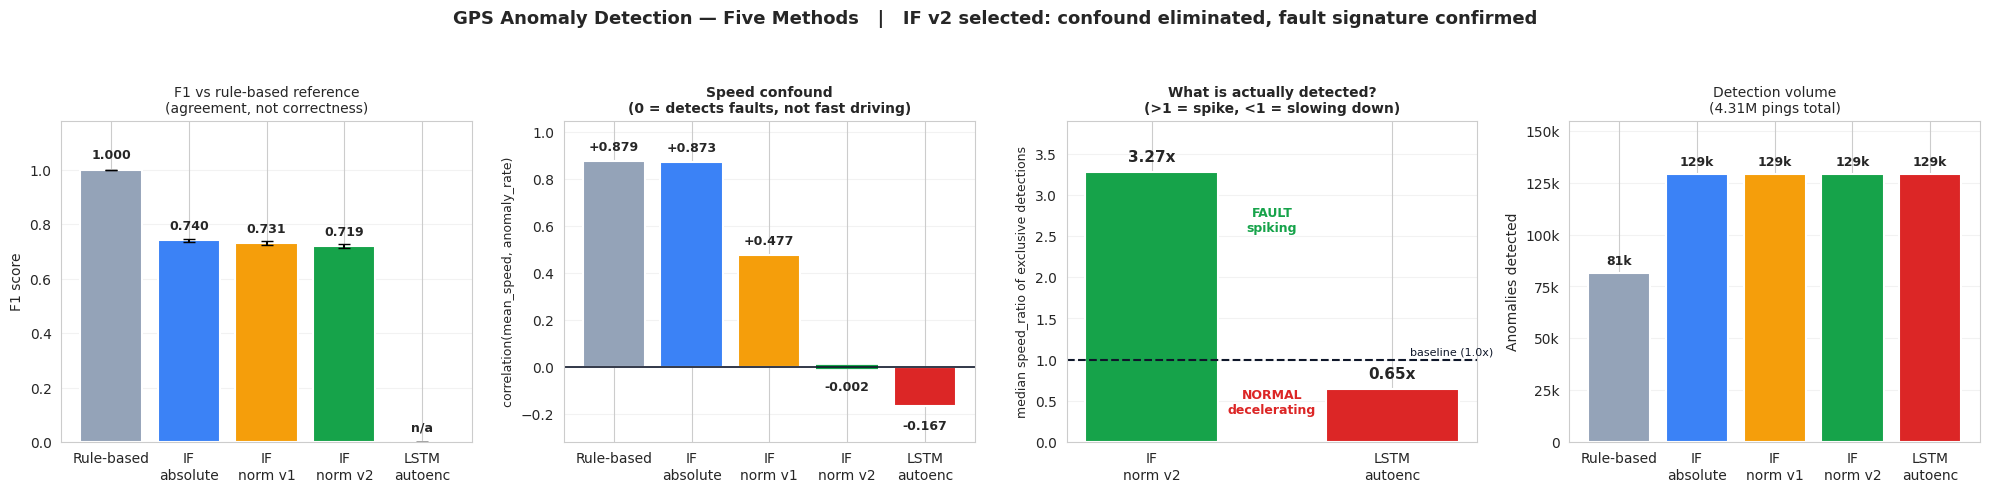

In [53]:
# ── MASTER COMPARISON FIGURE — all five methods ────────────────────────────
methods = ["Rule-based", "IF\nabsolute", "IF\nnorm v1", "IF\nnorm v2", "LSTM\nautoenc"]
colors  = ["#94a3b8", "#3b82f6", "#f59e0b", "#16a34a", "#dc2626"]

r_lstm_final = -0.167   # held-out taxis, iteration 2

f1_vals  = [1.000, cv_df["f1"].mean(), cv_v1["f1"].mean(), cv_v2["f1"].mean(), np.nan]
f1_errs  = [0, cv_df["f1"].std(), cv_v1["f1"].std(), cv_v2["f1"].std(), 0]
conf_vals = [r_rule, r_abs, r_norm, r_v2, r_lstm_final]
ratio_vals = [np.nan, np.nan, np.nan, 3.27, 0.648]
n_anom = [int(feat_df["rule_anomaly"].sum()),
          int(feat_df["iso_anomaly"].sum()),
          int(feat_df["iso_norm_anomaly"].sum()),
          int(feat_df["iso_v2_anomaly"].sum()),
          129214]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))

# Panel 1 — F1
ax = axes[0]
vals = [v if not np.isnan(v) else 0 for v in f1_vals]
ax.bar(methods, vals, yerr=f1_errs, color=colors, capsize=4, edgecolor="white", lw=1.5)
for i, v in enumerate(f1_vals):
    ax.text(i, (0 if np.isnan(v) else v) + 0.04,
            "n/a" if np.isnan(v) else f"{v:.3f}",
            ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 1.18)
ax.set_ylabel("F1 score", fontsize=10)
ax.set_title("F1 vs rule-based reference\n(agreement, not correctness)", fontsize=10)
ax.grid(axis="y", alpha=0.25)

# Panel 2 — Confound (the key panel)
ax = axes[1]
bars = ax.bar(methods, conf_vals, color=colors, edgecolor="white", lw=1.5)
bars[3].set_edgecolor("#16a34a"); bars[3].set_linewidth(3)
for i, v in enumerate(conf_vals):
    ax.text(i, v + (0.045 if v >= 0 else -0.10), f"{v:+.3f}",
            ha="center", fontsize=9, fontweight="bold")
ax.axhline(0, color="#0f172a", lw=1.2)
ax.set_ylim(-0.32, 1.05)
ax.set_ylabel("correlation(mean_speed, anomaly_rate)", fontsize=9)
ax.set_title("Speed confound\n(0 = detects faults, not fast driving)",
             fontsize=10, fontweight="bold")
ax.grid(axis="y", alpha=0.25)

# Panel 3 — Detection signature (the decisive panel)
ax = axes[2]
sig_methods = ["IF\nnorm v2", "LSTM\nautoenc"]
sig_vals = [3.27, 0.648]
sig_colors = ["#16a34a", "#dc2626"]
ax.bar(sig_methods, sig_vals, color=sig_colors, edgecolor="white", lw=1.5, width=0.55)
for i, v in enumerate(sig_vals):
    ax.text(i, v + 0.13, f"{v:.2f}x", ha="center", fontsize=11, fontweight="bold")
ax.axhline(1.0, color="#0f172a", ls="--", lw=1.5)
ax.text(1.42, 1.06, "baseline (1.0x)", fontsize=8, color="#0f172a", ha="right")
ax.text(0.5, 2.55, "FAULT\nspiking", ha="center", fontsize=9,
        color="#16a34a", fontweight="bold")
ax.text(0.5, 0.35, "NORMAL\ndecelerating", ha="center", fontsize=9,
        color="#dc2626", fontweight="bold")
ax.set_ylim(0, 3.9)
ax.set_ylabel("median speed_ratio of exclusive detections", fontsize=9)
ax.set_title("What is actually detected?\n(>1 = spike, <1 = slowing down)",
             fontsize=10, fontweight="bold")
ax.grid(axis="y", alpha=0.25)

# Panel 4 — Detection volume
ax = axes[3]
ax.bar(methods, n_anom, color=colors, edgecolor="white", lw=1.5)
for i, v in enumerate(n_anom):
    ax.text(i, v + 4000, f"{v/1000:.0f}k", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 155000)
ax.set_yticks([0, 25000, 50000, 75000, 100000, 125000, 150000])
ax.set_yticklabels(["0", "25k", "50k", "75k", "100k", "125k", "150k"])
ax.set_ylabel("Anomalies detected", fontsize=10)
ax.set_title("Detection volume\n(4.31M pings total)", fontsize=10)
ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "GPS Anomaly Detection — Five Methods   |   "
    "IF v2 selected: confound eliminated, fault signature confirmed",
    fontsize=13, fontweight="bold", y=1.06)
plt.tight_layout()
plt.savefig("/kaggle/working/final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 17. Conclusions

Five anomaly detection methods were evaluated on 4,311,098 GPS pings from 443 Porto taxis.

### Results

| Method | F1 (CV) | Confound r | Detection profile | Verdict |
|---|---|---|---|---|
| Rule-based | 1.000 (ref) | +0.879 | threshold crossing | biased, interpretable |
| IF absolute | 0.738 ± 0.003 | +0.873 | fleet-relative outlier | biased |
| IF normalised v1 | 0.731 ± 0.009 | +0.477 | partial correction | superseded |
| **IF normalised v2** | **0.718 ± 0.011** | **−0.002** | **3.27× own baseline** | **production** |
| LSTM autoencoder | — | −0.167 | 0.648× own baseline | rejected |

### 1. Unsupervised ML independently rediscovers hand-tuned physical rules

Isolation Forest, never shown the 80 m/s or 800 m thresholds, reproduces 96.0% of rule-based
detections. Convergence between an unsupervised model and rules derived from physics is evidence
that both track a real signal rather than noise.

It also detects 51,138 anomalies (+62.8%) invisible to any single threshold — characterised by
`rolling_std_speed` 15.2× the normal mean, i.e. violently erratic speed across the preceding five
pings. Threshold rules evaluate one variable at a time and are structurally incapable of
expressing this.

### 2. A speed confound affected every absolute-feature method — and was eliminated

Per-taxi analysis revealed that anomaly rate correlates with mean driving speed at r ≈ 0.87 for
**both** the rule-based detector and the initial ML model. Both were largely surfacing
*fast-driving vehicles* rather than *faulty sensors*.

The cause is arithmetic: `jump_distance ≈ speed × 15s`, giving `mean_speed` ↔ `mean_jump` a
correlation of 0.992. This is not an ML failure — the model inherited the bias from its features,
and the rule-based detector is marginally worse.

Expressing every feature relative to each vehicle's own baseline (`speed_z`, `jump_z`,
`speed_ratio`, `rolling_std_ratio`, `vx_z`, `vy_z`) reduced the confound to **r = −0.002**, a
99.8% reduction, at a cost of 0.020 F1. Since that F1 penalty comes precisely from declining to
flag vehicles decelerating normally, it represents improved fault specificity rather than degraded
detection.

An intermediate variant retaining raw `vx`/`vy` reached only r = +0.477. The residual was
hypothesised to be genuine physics — highways and tunnels degrade GPS quality — but normalising
the velocity components disproved this: the confound was almost entirely feature leakage.

### 3. The LSTM autoencoder detects rarity, not abnormality

A sequential model was tested on the hypothesis that temporal structure would reveal faults the
per-ping models miss. On held-out vehicles it achieved a **43.5× separation** between rule-based
anomalies and normal pings — a strong reconstruction result.

Examining *what* it flagged exclusively told a different story:

| | IF v2 | LSTM-only |
|---|---|---|
| Median `speed_ratio` | **3.27×** | **0.648×** |
| Interpretation | sudden spike | gentle deceleration |

`speed_ratio` below 1.0 means the vehicle is travelling *slower* than its own recent average —
decelerating into traffic, not malfunctioning. This is the same signature previously identified
as a false alarm.

**Root cause:** an autoencoder flags whatever is statistically rare. The training set is dominated
by steady-state cruising, so transitions reconstruct poorly regardless of sensor health. The model
learned *unusual*; the task requires *faulty*.

A second iteration added `accel_z` and `heading_change` to test whether the model simply lacked
the information to distinguish smooth deceleration from a discontinuity. The decision criterion was
set in advance: median `speed_ratio` above 1.0 would indicate genuine fault detection. It returned
**0.648** — further from the target than before. The missing feature was never the cause; rarity
is a property of the training distribution, not of feature representation.

The LSTM is therefore **rejected for production** while remaining a documented negative result.

### 4. Validation methodology

All Isolation Forest metrics use 5-fold GroupKFold grouped by vehicle, with scalers fitted on
training folds only. The LSTM's second iteration holds out 20% of vehicles entirely — its first
iteration used a random sequence split, which allowed the same vehicles into both train and
validation. Correcting this reduced the reported separation from 55.6× to 43.5×, quantifying the
leakage.

### 5. Limitations

**No human-labelled ground truth.** Reference labels come from the rule-based detector, so F1
measures *agreement between methods*, not absolute correctness. Isolation-Forest-only detections
count as false positives by construction — reported precision is a lower bound.

**Normalisation assumes full vehicle history.** Per-vehicle statistics are computed across each
taxi's complete ping record, so a scored ping contributes to its own baseline. `GroupKFold`
prevents cross-vehicle contamination and one ping's influence on a ~10,000-ping baseline is
negligible, but production deployment requires either a warm-up period per vehicle or
expanding-window statistics.

**Dataset scope.** 200 trips per taxi (4.3M of ~83M available pings). The ±0.003 cross-validation
standard deviation indicates convergence, but this was not verified at full scale.

### 6. Production recommendation

Deploy **Isolation Forest v2** alongside the existing rule-based detector. The rules remain as a
fast, fully interpretable safety net explainable to a fleet operator in one sentence; v2 runs in
parallel to surface the multivariate cases the rules cannot reach, feeding the LLM agent for
diagnosis.

For maintenance prioritisation specifically, v2 should be preferred — it is the only variant that
distinguishes a faulty sensor from a fast driver, which is the difference between dispatching a
mechanic to the right vehicle and the wrong one.

---

### Next steps

- **Deploy `isolation_forest_normalised_v2.pkl` into the Spark pipeline** with running per-vehicle
  statistics and a warm-up threshold
- **Balanced-regime LSTM training** — sample equally across deceleration, steady and acceleration
  regimes to test whether the rarity problem is solvable at the data level rather than the feature
  level
- **Sequence-prediction architecture** — predict ping *n+1* from pings 1..*n* rather than
  reconstructing the window; prediction error is closer to a fault definition than reconstruction
  error
- **Re-run at full dataset scale** to confirm the ±0.003 stability holds